# NYC Rideshare Seasonal Demand Patterns

**Course:** BA780  

**Team:** Group 6

**Section:** B6

**Team Members:** Elizabeth Lukina, Sally Hao, Taaseen Islam, Teddy Tessel, Melis Gurbuz  

**Project Manager:** Melis Gurbuz

## Data Sources and Terms of Use

- **Rideshare data:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page). We use a 1% random sample from each monthly High Volume For-Hire Vehicle file from January 2023 through December 2025, covering 36 months.
- **Location data:** [NYC TLC Taxi Zone Lookup Table](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv), used to match pickup location IDs with zone names and boroughs.
- **Weather data:** [NOAA Local Climatological Data](https://www.ncei.noaa.gov/products/land-based-station/local-climatological-data), using LaGuardia Airport daily summaries for 2023–2025.
- **TLC terms of use:** [NYC.gov Terms of Use](https://www.nyc.gov/main/terms-of-use). Our sampled data and calculated measures are modifications of the original records.

# 1. Business Problem Definition

## 1.1 Problem Definition
This project looks at when and where rideshare activity is highest across New York City to help Uber make better decisions about driver availability in comparison to their competitor Lyft. Understanding how ride activity and passenger wait times change by season, year, location, and weather patterns can help Uber better match drivers with riders. The goal is to identify clear patterns in trip volume, wait times, and driver pay and use that to recommend when and where more drivers may be needed.

## 1.2 Executive Summary
This project analyzes 7,155,498 NYC rideshare trips from 1% monthly samples across 2023–2025, matched with pickup-zone information and daily weather data, to inform Uber’s driver availability planning. Winter activity grew in both yearly comparisons while August was consistently the quietest month, and Friday and Saturday evenings had high pickup activity. Passenger waits peaked around 4 AM in 2025, while Uber’s median wait exceeded Lyft’s by approximately two minutes for 5–10 mile trips at LaGuardia during 7–8 PM. Daily precipitation showed only small overall differences in waits and base fares. After analyzing Uber compared to Lyft, Uber should review morning service and airport pickup coordination to improve their services.


# 2. Data Overview and Preparation

## 2.1 Data Access and Running Instructions

The [sampled dataset folder](https://drive.google.com/drive/folders/1B5RgYFus_WsXbsMI-O2wQXM4dcIUIt3_?usp=drive_link)
contains 36 monthly files, each representing a 1% random sample of NYC
rideshare trips from January 2023 through December 2025.

The [sampling notebook](https://colab.research.google.com/drive/1wv3SVu2i7ntKiKCfwRmoRl3HJwgceg7m?usp=drive_link)
documents how the samples were created.

In order to get this notebook to run in your enviroment:
Add the sampled dataset folder to your Google Drive, mount your Drive, and update the variable folder to match its location. Run the cells
in order. Weather files are loaded directly from NOAA.


## 2.2 Data Dictionary

**Rideshare: Platform and Location**

| Variable | Meaning | Values |
|---|---|---|
| `service_license` | TLC service code | HV0003 = Uber; HV0005 = Lyft |
| `platform` | Platform name | Uber or Lyft |
| `pickup_zone_id` | Pickup location ID | TLC zone number |
| `dropoff_zone_id` | Drop-off location ID | TLC zone number |
| `pickup_zone` | Pickup zone name from the TLC lookup table | Zone name |
| `pickup_borough` | Borough associated with the pickup zone | Borough name |

**Rideshare: Dates and Times**

| Variable | Meaning | Values |
|---|---|---|
| `request_datetime` | Time the passenger requested the trip | Date and time |
| `pickup_datetime` | Time the trip started | Date and time |
| `dropoff_datetime` | Time the trip ended | Date and time |
| `source_month` | Month of the sampled source file | YYYY-MM |
| `trip_date` | Pickup date, stored at midnight | Date |
| `year` | Pickup year | 2023, 2024, or 2025 |
| `month` | Pickup month | 1–12 |
| `pickup_hour` | Pickup hour | 0–23 |
| `hour` | Copy of pickup_hour used in some charts | 0–23 |
| `day` | Pickup day of the week | Monday–Sunday |
| `season` | Season assigned using the pickup month | Winter, Spring, Summer, or Fall |

**Rideshare: Trip Measurements and Checks**

| Variable | Meaning | Unit or values |
|---|---|---|
| `trip_miles` | Reported trip distance | Miles |
| `trip_duration_seconds` | Reported trip duration, originally named trip_time | Seconds |
| `wait_time_seconds` | Pickup time minus request time; negative values are set to missing | Seconds |
| `wait_min` | Passenger waiting time converted to minutes | Minutes |
| `pickup_before_request` | Whether pickup was recorded before the request | True or False |
| `dropoff_before_pickup` | Whether drop-off was recorded before pickup | True or False |
| `calculated_duration` | Drop-off time minus pickup time in Q15 | Seconds |
| `duration_difference` | Absolute difference between calculated and reported trip duration in Q15 | Seconds |
| `distance_group` | Trip-distance ranges used in Q9 | Over 0–2, over 2–5, over 5–10, and over 10 miles |
| `shared_request_flag` | Whether a shared ride was requested | Y, N, or missing |
| `shared_match_flag` | Whether the trip was matched as a shared ride | Y, N, or missing |

**Rideshare: Financial Columns**

| Variable | Meaning | Unit |
|---|---|---|
| `base_passenger_fare` | Base passenger fare before separately reported charges | US dollars |
| `driver_pay` | Reported driver payment before driver expenses | US dollars |
| `tolls` | Reported toll charges | US dollars |
| `bcf` | Black Car Fund charge | US dollars |
| `sales_tax` | Reported sales tax | US dollars |
| `congestion_surcharge` | Reported congestion surcharge | US dollars |
| `airport_fee` | Reported airport fee | US dollars |
| `tips` | Reported tips | US dollars |
| `cbd_congestion_fee` | Central Business District congestion fee | US dollars |
| `fare_per_mile` | Base passenger fare divided by trip miles | US dollars per mile |
| `pay_per_trip_hour` | Driver pay divided by reported trip duration in hours | US dollars per recorded trip hour |

**Daily Weather: LaGuardia Airport**

| Variable | Meaning | Unit or values |
|---|---|---|
| `REPORT_TYPE` | Source report code used to select daily summaries | SOD = Summary of Day |
| `DATE` | Date of the daily weather summary | Date |
| `DailyPrecipitation` | Daily precipitation amount; trace amounts become missing numerically and are identified by the trace flag | Millimeters |
| `DailyAverageDryBulbTemperature` | Daily average air temperature | Degrees Celsius |
| `DailyAverageWindSpeed` | Daily average wind speed | Meters per second |
| `trace_precipitation` | Whether the source recorded a trace amount as T | True or False |
| `weather_condition` | Classification based on daily precipitation | Dry or Precipitation |

**Summary Measures**

| Variable | Meaning | Unit |
|---|---|---|
| `sampled_trips` | Number of sampled trips in a date or group | Trips |
| `calendar_days` | Number of calendar days in the period | Days |
| `days` | Number of dates in a weather category within the period analyzed | Days |
| `average_daily_trips` | Sampled trips divided by calendar days or days in the relevant weather category | Sampled trips per day |
| `median_wait` | Group median passenger wait used in Q6 and Q8 | Minutes |
| `valid_waits` | Number of trips with nonmissing waits in a group | Trips |
| `median` | Median of the measure being summarized, such as wait minutes, fare per mile, or pay per trip hour | Depends on the measure |
| `count` | Number of nonmissing observations used to summarize a measure | Trips |
| `lyft_minus_uber` | Lyft median wait minus Uber median wait | Minutes |



## 2.3 Loading and Inspecting Rideshare Data

We combined 1% monthly random samples from January 2023 through December 2025 and removed one exact duplicate, retaining 7,155,498 trips. We validated pickup dates and set negative request-to-pickup times to missing. Trips with invalid measurements remained available for trip counts but were excluded from the corresponding measurement analyses. Joining the Taxi Zone Lookup Table added pickup-zone and borough labels, while removing unnecessary table copies reduced memory use.

**Setup and loading monthly samples**


In [1]:
from google.colab import drive
drive.mount('/content/gdrive')
import pandas as pd
import os
import gc
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [2]:
folder = '/content/gdrive/MyDrive/BA780 Group 6/Random Sampled Datasets'

In [3]:
monthly_data = []

for year in [2023, 2024, 2025]:
    for month in range(1, 13):
        period = f'{year}-{month:02d}'

        data = pd.read_parquet(
            f'{folder}/fhvhv_tripdata_{period}_sample_1pct.parquet'
        )

        data['source_month'] = period
        monthly_data.append(data)

rideshare = pd.concat(monthly_data, ignore_index=True)
starting_rows = len(rideshare)
original_counts = rideshare.groupby('source_month').size()
print('Loaded rows:', starting_rows)
print('Loaded months:', len(original_counts))
display(original_counts)
del monthly_data, data
gc.collect()

Loaded rows: 7155499
Loaded months: 36


,0
source_month,
2023-01,184790
2023-02,179610
2023-03,204135
2023-04,191449
2023-05,198477
2023-06,193666
2023-07,191321
2023-08,183222
2023-09,198511


0

 The monthly samples were combined into a dataset containing 7,155,499 trip records before cleaning. This provides a three-year sample for examining seasonal demand patterns in NYC. We also verified the number of records for each month to check the dataset's coverage.

**Checking data types and missing values**


We examined the dataset's structure, checked data types, identified missing values across columns, and looked for duplicate records. This initial inspection helps identify potential data quality issues before cleaning. We want to ensure that the variables have appropriate formats and understand which columns may require additional cleaning.

In [4]:
rideshare.info(show_counts=True)
display(rideshare.head())
display(rideshare.isnull().sum())
print('Exact duplicates:', rideshare.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7155499 entries, 0 to 7155498
Data columns (total 26 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   hvfhs_license_num     7155499 non-null  object        
 1   dispatching_base_num  7155499 non-null  object        
 2   originating_base_num  5228549 non-null  object        
 3   request_datetime      7155499 non-null  datetime64[us]
 4   on_scene_datetime     5794198 non-null  datetime64[us]
 5   pickup_datetime       7155499 non-null  datetime64[us]
 6   dropoff_datetime      7155499 non-null  datetime64[us]
 7   PULocationID          7155499 non-null  int64         
 8   DOLocationID          7155499 non-null  int64         
 9   trip_miles            7155499 non-null  float64       
 10  trip_time             7155499 non-null  int64         
 11  base_passenger_fare   7155499 non-null  float64       
 12  tolls                 7155499 non-null  fl

,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag,source_month,cbd_congestion_fee
0,HV0003,B03404,B03404,2023-01-03 20:00:53,2023-01-03 20:05:02,2023-01-03 20:05:22,2023-01-03 20:16:03,108,55,2.360,...,0.0,1.0,8.40,N,N,,N,N,2023-01,NaN
1,HV0003,B03404,B03404,2023-01-24 19:01:16,2023-01-24 19:03:40,2023-01-24 19:05:41,2023-01-24 19:14:33,260,129,0.880,...,0.0,0.0,6.59,N,N,,N,N,2023-01,NaN
2,HV0003,B03404,B03404,2023-01-07 23:32:36,2023-01-07 23:33:20,2023-01-07 23:35:20,2023-01-07 23:49:52,170,232,2.940,...,0.0,0.0,11.12,N,N,,N,N,2023-01,NaN
3,HV0005,B03406,None,2023-01-15 17:58:21,NaT,2023-01-15 18:04:10,2023-01-15 18:12:23,68,246,1.432,...,0.0,0.0,6.04,N,N,N,N,N,2023-01,NaN
4,HV0005,B03406,None,2023-01-23 08:22:06,NaT,2023-01-23 08:27:12,2023-01-23 08:35:11,223,223,1.507,...,0.0,0.0,6.01,N,N,N,N,N,2023-01,NaN


,0
hvfhs_license_num,0
dispatching_base_num,0
originating_base_num,1926950
request_datetime,0
on_scene_datetime,1361301
pickup_datetime,0
dropoff_datetime,0
PULocationID,0
DOLocationID,0
trip_miles,0


Exact duplicates: 1


The dataset contains 7,155,499 records and 26 columns. Most variables have no missing values, but some columns have substantial missing data. For example, originating_base_num has approximately 1.93 million missing values, on_scene_datetime has approximately 1.36 million, and cbd_congestion_fee has approximately 4.72 million. We also identified one exact duplicate record. These findings show that missing values are concentrated in specific variables rather than spread throughout the dataset, allowing us to handle them based on their relevance to our analysis.

**Removing exact duplicates**



We checked for identical records across all columns and removed exact duplicates using drop_duplicates().Duplicate records could lead to double-counting rides and overestimating trip demand. Removing them helps ensure accurate comparisons of rideshare activity across different months and seasons.

In [5]:
print('Duplicates removed:', rideshare.duplicated().sum())

rideshare = rideshare.drop_duplicates()

print('Rows remaining:', len(rideshare))

Duplicates removed: 1
Rows remaining: 7155498


Duplicate records were not a major issue since in the dataset of over 7.1 million sampled rides there was only one exact duplicate. Missing values were concentrated in specific columns rather than throughout the dataset, this way they can be handled based on how each variable would be used later.

## 2.4 Cleaning and Preparing Rideshare Data


**Standardizing categorical values**


We standardized five categorical variables related to shared rides, Access-A-Ride, and wheelchair-accessible vehicles (WAV). We converted the values to strings, removed extra spaces, changed letters to uppercase, and replaced empty strings with missing values. This ensures that categories are recorded consistently and prevents formatting differences from creating separate categories. We also wanted to distinguish missing values from actual responses rather than incorrectly treating them as "Yes" or "No."

In [6]:
flag_columns = ['shared_request_flag', 'shared_match_flag', 'access_a_ride_flag', 'wav_request_flag', 'wav_match_flag']
for col in flag_columns:
    rideshare[col] = rideshare[col].astype('string').str.strip().str.upper()
    rideshare[col] = rideshare[col].replace('', pd.NA)
    print(col)
    print(rideshare[col].value_counts(dropna=False))

shared_request_flag
shared_request_flag
N    6936534
Y     218964
Name: count, dtype: Int64
shared_match_flag
shared_match_flag
N    7057403
Y      98095
Name: count, dtype: Int64
access_a_ride_flag
access_a_ride_flag
N       5800021
<NA>    1350413
Y          5064
Name: count, dtype: Int64
wav_request_flag
wav_request_flag
N    7137292
Y      18206
Name: count, dtype: Int64
wav_match_flag
wav_match_flag
N    6536872
Y     618626
Name: count, dtype: Int64


Standardizing the categorical flags showed that most rides were not shared, WAV requests were uncommon, and some Access-A-Ride values were missing. We kept missing values separate so they would not be incorrectly treated as “Yes” or “No.”

**Reviewing missing values across months**



We grouped the dataset by month and calculated the proportion of missing values in four variables: originating_base_num, on_scene_datetime, access_a_ride_flag, and cbd_congestion_fee. We wanted to understand whether missing values were consistent over time or concentrated in particular months. This helps us identify possible changes in data reporting and determine whether missing values could affect comparisons across seasons and years.

In [7]:
display(rideshare.groupby('source_month')[['originating_base_num', 'on_scene_datetime', 'access_a_ride_flag', 'cbd_congestion_fee']].agg(lambda x: x.isnull().mean() * 100))

,originating_base_num,on_scene_datetime,access_a_ride_flag,cbd_congestion_fee
source_month,,,,
2023-01,26.505222,26.505222,73.451485,100.0
2023-02,26.037526,26.037526,73.924614,100.0
2023-03,28.570799,28.570799,71.389522,100.0
2023-04,26.693271,26.693271,73.269121,100.0
2023-05,27.836979,27.836979,72.117172,100.0
2023-06,28.407671,28.407671,71.537596,100.0
2023-07,28.269244,28.269244,71.670648,100.0
2023-08,28.166923,28.166923,71.762125,100.0
2023-09,27.801482,27.801482,72.138572,100.0


Missing values were not consistent across the three year period particularly for Access-A-Ride field, which has a lot of missing data during 2023 before becoming complete. This suggests that some missing values reflect changes in data reporting over time rather than random missing records.

**Checking distance, duration, and payments**


We checked for negative and zero values in trip distance and duration, as well as negative passenger fares and driver payments. We also inspected the first 20 records with zero distance or duration to better understand these observations. We wanted to identify potentially incorrect or unusual trip measurements that could affect our analysis. In particular, zero-distance and zero-duration trips may distort distance and speed calculations, even though they may still represent recorded ride requests.

In [8]:
print("Negative miles:", (rideshare["trip_miles"] < 0).sum())
print("Negative duration:", (rideshare["trip_time"] < 0).sum())
print("Zero miles:", (rideshare["trip_miles"] == 0).sum())
print("Zero duration:", (rideshare["trip_time"] == 0).sum())
print("Negative base fares:", (rideshare["base_passenger_fare"] < 0).sum())
print("Negative driver pay:", (rideshare["driver_pay"] < 0).sum())

zero_trips = rideshare.loc[(rideshare["trip_miles"] == 0) | (rideshare["trip_time"] == 0)]

display(zero_trips[["trip_miles", "trip_time", "base_passenger_fare", "driver_pay", "pickup_datetime", "dropoff_datetime"]].head(20))

Negative miles: 0
Negative duration: 0
Zero miles: 1073
Zero duration: 1
Negative base fares: 973
Negative driver pay: 49


,trip_miles,trip_time,base_passenger_fare,driver_pay,pickup_datetime,dropoff_datetime
9921,0.0,11,15.49,8.47,2023-01-28 23:51:32,2023-01-28 23:51:43
20480,0.0,3697,65.43,34.84,2023-01-31 07:35:00,2023-01-31 08:36:37
20612,0.0,2214,26.03,21.35,2023-01-24 11:59:25,2023-01-24 12:36:19
20926,0.0,50,11.44,0.00,2023-01-02 21:37:05,2023-01-02 21:37:55
37596,0.0,26,6.79,5.47,2023-01-03 23:52:37,2023-01-03 23:53:03
43082,0.0,295,11.54,0.00,2023-01-23 21:14:33,2023-01-23 21:19:28
48443,0.0,230,7.19,7.02,2023-01-25 15:12:05,2023-01-25 15:15:55
54396,0.0,1315,25.37,19.03,2023-01-28 03:44:10,2023-01-28 04:06:05
59862,0.0,122,23.30,16.66,2023-01-23 18:16:59,2023-01-23 18:19:01
60843,0.0,244,5.75,12.01,2023-01-08 21:09:56,2023-01-08 21:14:00


This inspection helps distinguish unusual trip measurements from records that should be removed entirely. We decided to retain zero-mile trips in overall demand counts but exclude trips with invalid distance or duration values from the relevant measurement analyses. This allows us to preserve trip records for seasonal demand comparisons without letting invalid measurements distort distance and speed summaries.

**Preparing passenger wait times**


We checked for trips where pickup occurred before the request or drop-off occurred before pickup. We then calculated passenger waiting time in seconds by subtracting the request time from the pickup time. Negative waiting times were replaced with missing values (NaN), and we examined how frequently these inconsistencies occurred across months. We wanted to ensure that waiting times were calculated using valid timestamps. Incorrect time sequences could distort average waiting times and lead to misleading comparisons across seasons and years.

In [9]:
rideshare['pickup_before_request'] = rideshare['pickup_datetime'] < rideshare['request_datetime']
rideshare['dropoff_before_pickup'] = rideshare['dropoff_datetime'] < rideshare['pickup_datetime']
print('Pickup before request:', rideshare['pickup_before_request'].sum())
print('Dropoff before pickup:', rideshare['dropoff_before_pickup'].sum())
rideshare['wait_time_seconds'] = (rideshare['pickup_datetime'] - rideshare['request_datetime']).dt.total_seconds()
rideshare.loc[rideshare['pickup_before_request'], 'wait_time_seconds'] = float('nan')
display(rideshare.groupby('source_month')['pickup_before_request'].agg(['sum', 'mean']))
display(rideshare.loc[rideshare['pickup_before_request'], ['source_month', 'request_datetime', 'pickup_datetime', 'wait_time_seconds']].head(20))

Pickup before request: 74328
Dropoff before pickup: 302


,sum,mean
source_month,,
2023-01,2273,0.012300
2023-02,1842,0.010256
2023-03,2037,0.009979
2023-04,1554,0.008117
2023-05,1874,0.009442
2023-06,1762,0.009098
2023-07,1586,0.008290
2023-08,1710,0.009333
2023-09,1882,0.009481


,source_month,request_datetime,pickup_datetime,wait_time_seconds
140,2023-01,2023-01-27 21:50:00,2023-01-27 21:41:59,NaN
162,2023-01,2023-01-28 08:40:00,2023-01-28 08:28:21,NaN
189,2023-01,2023-01-28 13:20:00,2023-01-28 13:09:30,NaN
232,2023-01,2023-01-25 15:30:00,2023-01-25 15:17:26,NaN
254,2023-01,2023-01-20 22:20:00,2023-01-20 22:12:59,NaN
298,2023-01,2023-01-21 05:10:00,2023-01-21 04:59:20,NaN
341,2023-01,2023-01-09 08:10:00,2023-01-09 08:01:42,NaN
382,2023-01,2023-01-16 03:50:00,2023-01-16 03:39:24,NaN
392,2023-01,2023-01-05 08:30:00,2023-01-05 08:22:01,NaN
412,2023-01,2023-01-18 14:15:00,2023-01-18 13:57:14,NaN


A small number of records contained impossible time sequences, including 74,328 trips where pickup occurred before the recorded request and 302 where drop-off occurred before pickup. Invalid request-to-pickup times were excluded from the wait-time calculation so they would not impact later analysis.

**Reviewing duration differences**


We calculated trip duration using the difference between drop-off and pickup timestamps and compared it with the recorded trip_time variable. We identified trips with differences greater than 60 seconds and checked for drop-offs occurring before pickups. We wanted to identify inconsistencies between recorded and calculated trip durations that could affect our analysis. Checking one-hour differences also helps detect potential timestamp issues, such as daylight saving time adjustments.

In [10]:
calculated_duration = (rideshare['dropoff_datetime'] - rideshare['pickup_datetime']).dt.total_seconds()
duration_difference = calculated_duration - rideshare['trip_time']
print('Duration differences over 60 seconds:', (duration_difference.abs() > 60).sum())
print('Dropoff before pickup:', rideshare['dropoff_before_pickup'].sum())
one_hour_difference = duration_difference.abs().between(3590, 3610)
display(rideshare.loc[one_hour_difference].groupby('source_month').size())
display(rideshare.loc[one_hour_difference, ['pickup_datetime', 'dropoff_datetime', 'trip_time']].head(20))

Duration differences over 60 seconds: 711
Dropoff before pickup: 302


,0
source_month,
2023-03,84
2023-11,102
2024-03,86
2024-11,92
2025-03,94
2025-11,113


,pickup_datetime,dropoff_datetime,trip_time
365412,2023-03-12 01:59:00,2023-03-12 03:11:43,763
365711,2023-03-12 01:59:45,2023-03-12 03:15:39,954
368411,2023-03-12 01:50:07,2023-03-12 03:01:19,672
368491,2023-03-12 01:50:37,2023-03-12 03:03:15,758
369002,2023-03-12 01:59:38,2023-03-12 03:18:38,1140
371385,2023-03-12 01:52:34,2023-03-12 03:11:11,1117
373309,2023-03-12 01:41:15,2023-03-12 03:05:35,1460
374096,2023-03-12 01:40:02,2023-03-12 03:05:10,1508
379269,2023-03-12 01:37:57,2023-03-12 03:07:53,1796
380103,2023-03-12 01:27:08,2023-03-12 03:06:24,2356


Comparing calculated and recorded trip durations allowed us to identify potential inconsistencies in the dataset, including trips with impossible time sequences and differences of approximately one hour. These discrepancies may be related to timestamp reporting or daylight saving time adjustments. Identifying them helps us determine which duration measurements require further validation before being used in trip-duration and speed analyses.

**Creating calendar fields**



We checked whether pickup dates matched their corresponding source months, identified missing pickup timestamps, and checked for trips outside our study period (2023–2025). We then extracted the trip date, year, month, and pickup hour from the pickup timestamps.We wanted to ensure that trips were assigned to the correct time periods and create variables that allow us to analyze rideshare demand across different years, seasons, months, and hours of the day.

In [11]:
pickup_month = rideshare['pickup_datetime'].dt.strftime('%Y-%m')
print('Pickup/source month mismatch:', (pickup_month != rideshare['source_month']).sum())
print('Missing pickup dates:', rideshare['pickup_datetime'].isnull().sum())
outside_period = rideshare['pickup_datetime'].notna() & ((rideshare['pickup_datetime'] < '2023-01-01') | (rideshare['pickup_datetime'] >= '2026-01-01'))
print('Outside period:', outside_period.sum())
rideshare['trip_date'] = rideshare['pickup_datetime'].dt.normalize()
rideshare['year'] = rideshare['pickup_datetime'].dt.year
rideshare['month'] = rideshare['pickup_datetime'].dt.month
rideshare['pickup_hour'] = rideshare['pickup_datetime'].dt.hour

Pickup/source month mismatch: 0
Missing pickup dates: 0
Outside period: 0


We created standardized calendar variables that allow us to group and compare rideshare activity across different time periods. Checking pickup dates against source months and the study period also helps identify records that may be assigned to incorrect periods. These variables provide the foundation for identifying seasonal demand patterns and peak pickup hours.

**Selecting and renaming columns**


 We selected the variables most relevant to our analysis, including trip timestamps, pickup and drop-off locations, trip distance, and duration. We created a separate dataset called rideshare_clean and renamed selected columns to make them easier to understand. We also removed the original dataset from memory after creating the new one. We wanted to simplify the dataset by focusing on the information needed to investigate seasonal rideshare demand and waiting times. Renaming variables improves readability, while removing the original dataset from memory helps reduce memory usage when working with a large number of records.

In [12]:
analysis_columns = ['hvfhs_license_num', 'request_datetime', 'pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID', 'trip_miles', 'trip_time', 'base_passenger_fare', 'tolls', 'bcf', 'sales_tax', 'congestion_surcharge', 'airport_fee', 'tips', 'driver_pay', 'cbd_congestion_fee', 'shared_request_flag', 'shared_match_flag', 'source_month', 'trip_date', 'year', 'month', 'pickup_hour', 'wait_time_seconds', 'pickup_before_request', 'dropoff_before_pickup']
rideshare_clean = rideshare.loc[:, analysis_columns].copy()
rideshare_clean = rideshare_clean.rename(columns={'hvfhs_license_num': 'service_license', 'PULocationID': 'pickup_zone_id', 'DOLocationID': 'dropoff_zone_id', 'trip_time': 'trip_duration_seconds'})
print(rideshare_clean.columns.tolist())

['service_license', 'request_datetime', 'pickup_datetime', 'dropoff_datetime', 'pickup_zone_id', 'dropoff_zone_id', 'trip_miles', 'trip_duration_seconds', 'base_passenger_fare', 'tolls', 'bcf', 'sales_tax', 'congestion_surcharge', 'airport_fee', 'tips', 'driver_pay', 'cbd_congestion_fee', 'shared_request_flag', 'shared_match_flag', 'source_month', 'trip_date', 'year', 'month', 'pickup_hour', 'wait_time_seconds', 'pickup_before_request', 'dropoff_before_pickup']


In [13]:
del rideshare
gc.collect()

104

We created a more focused dataset containing the variables needed for our analysis while preserving the original trip information in the selected records. The updated column names make the dataset easier to interpret and work with. Removing the larger original DataFrame also helps reduce memory usage and makes subsequent analysis more manageable.

## 2.5 Checking and Saving the Cleaned Data


**Identifying usable measurements**


We created separate conditions to identify valid records for trip distance, duration, waiting time, passenger fare, and driver pay. We considered positive distances and durations, non-missing waiting times, and non-negative fares and driver payments as usable for their respective analyses. We wanted to ensure that invalid measurements would not distort our results while preserving as many trip records as possible. Instead of removing entire rows, we identified which records could be used for each analysis separately.

In [14]:
valid_distance = rideshare_clean['trip_miles'] > 0
valid_duration = rideshare_clean['trip_duration_seconds'] > 0
valid_wait = rideshare_clean['wait_time_seconds'].notna()
valid_fare = rideshare_clean['base_passenger_fare'] >= 0
valid_driver_pay = rideshare_clean['driver_pay'] >= 0
print('Demand records:', len(rideshare_clean))
print('Usable distance records:', valid_distance.sum())
print('Usable duration records:', valid_duration.sum())
print('Usable wait records:', valid_wait.sum())
print('Usable base fare records:', valid_fare.sum())
print('Usable driver pay records:', valid_driver_pay.sum())

Demand records: 7155498
Usable distance records: 7154425
Usable duration records: 7155497
Usable wait records: 7081170
Usable base fare records: 7154525
Usable driver pay records: 7155449


We established separate validity criteria for each measurement rather than excluding trips with incomplete or invalid information from the entire dataset. This allows us to retain all 7,155,498 records for demand analysis while using only appropriate observations for distance, duration, waiting time, fare, and driver pay calculations. This approach helps preserve the sample size and improves the reliability of our comparisons.

**Reviewing unusual trip speeds**


 We calculated average trip speeds using records with positive distances and durations. We then examined the distribution of speeds, including the 1st, 50th, 95th, and 99th percentiles, and inspected the 20 highest values.
 We wanted to identify unusually high speeds that could indicate errors in trip distance or duration measurements. This helps us assess data quality and determine whether extreme observations could affect our analysis.

In [15]:
speed = rideshare_clean.loc[valid_distance & valid_duration, 'trip_miles'] / (rideshare_clean.loc[valid_distance & valid_duration, 'trip_duration_seconds'] / 3600)
display(speed.describe(percentiles=[0.01, 0.5, 0.95, 0.99]))
display(speed.sort_values(ascending=False).head(20))

,0
count,7.154425e+06
mean,1.359800e+01
std,7.195637e+00
min,1.103617e-02
1%,3.885093e+00
50%,1.151454e+01
95%,2.864959e+01
99%,3.751186e+01
max,1.656000e+02


,0
4530398,165.600000
6761847,147.600000
5700240,108.118812
1186645,88.473275
1277044,84.479092
791091,84.303580
2575260,84.123871
1104428,82.600000
3191602,81.801920
1419293,80.929377


 Examining the speed distribution helps us identify potentially unrealistic trip measurements and understand the presence of extreme values. Rather than automatically removing unusually high speeds, we retained the records for further consideration because extreme observations do not necessarily indicate errors. This avoids introducing arbitrary filtering decisions that could affect our results.

**Checking final row counts and missing values**


We compared the number of records before and after cleaning for each month, calculated how many rows were removed, and checked the remaining missing values in the cleaned dataset. We wanted to verify that the cleaning process preserved most of the original trip records and did not unintentionally remove large amounts of data. We also wanted to identify any remaining missing values that may need to be considered during the analysis.

In [16]:
cleaning_summary = pd.DataFrame({'loaded_rows': original_counts, 'retained_rows': rideshare_clean.groupby('source_month').size()})
cleaning_summary['removed_rows'] = cleaning_summary['loaded_rows'] - cleaning_summary['retained_rows']
display(cleaning_summary)
print('Loaded rows:', starting_rows)
print('Retained rows:', len(rideshare_clean))
display(rideshare_clean.isnull().sum())


,loaded_rows,retained_rows,removed_rows
source_month,,,
2023-01,184790,184790,0
2023-02,179610,179610,0
2023-03,204135,204135,0
2023-04,191449,191449,0
2023-05,198477,198477,0
2023-06,193666,193666,0
2023-07,191321,191321,0
2023-08,183222,183222,0
2023-09,198511,198511,0


Loaded rows: 7155499
Retained rows: 7155498


,0
service_license,0
request_datetime,0
pickup_datetime,0
dropoff_datetime,0
pickup_zone_id,0
dropoff_zone_id,0
trip_miles,0
trip_duration_seconds,0
base_passenger_fare,0
tolls,0


The cleaning process retained 7,155,498 of the original 7,155,499 trip records, with only one exact duplicate removed. This confirms that nearly all observations were preserved for seasonal demand analysis. Missing values and invalid measurements were handled selectively rather than removing entire trip records, allowing us to maintain a large sample while preparing the data for further analysis.

**Saving the cleaned dataset**


We saved the cleaned rideshare dataset as a Parquet file and exported the cleaning summary as a CSV file to Google Drive. The cleaning summary contains the number of original, retained, and removed records for each month. We wanted to preserve the cleaned dataset for further analysis without repeating the entire cleaning process. Saving the cleaning summary also allows us to document the changes made to the original data.

In [17]:
output_folder = '/content/gdrive/MyDrive/Cleaned Datasets'
os.makedirs(output_folder, exist_ok=True)
rideshare_clean.to_parquet(f'{output_folder}/rideshare_analysis_ready.parquet', index=False)
cleaning_summary.to_csv(f'{output_folder}/cleaning_summary_reviewed.csv')
print('Saved to:', output_folder)

Saved to: /content/gdrive/MyDrive/Cleaned Datasets


The cleaned dataset and cleaning summary are prepared for storage in Google Drive.

In [18]:
del calculated_duration, duration_difference, one_hour_difference, pickup_month, outside_period, zero_trips, speed
gc.collect()

24

We deleted unnecessary variables as they are no longer needed; Q15 calculates its own duration checks.


## 2.6 Preparing Daily Weather Data

We use daily precipitation, average temperature, and average wind speed
from LaGuardia Airport for 2023–2025 to examine associations with
rideshare activity and passenger waits.

Weather measurements come from LaGuardia Airport and serve as an
approximation of daily NYC conditions; they may not capture weather
differences across pickup zones.

In [19]:
weather_2023 = pd.read_csv("https://www.ncei.noaa.gov/oa/local-climatological-data/v2/access/2023/LCD_USW00014732_2023.csv")

weather_2024 = pd.read_csv("https://www.ncei.noaa.gov/oa/local-climatological-data/v2/access/2024/LCD_USW00014732_2024.csv")

weather_2025 = pd.read_csv("https://www.ncei.noaa.gov/oa/local-climatological-data/v2/access/2025/LCD_USW00014732_2025.csv")

weather = pd.concat([weather_2023, weather_2024, weather_2025], ignore_index=True)


/tmp/ipykernel_69388/1588312580.py:1: DtypeWarning: Columns (41,62) have mixed types. Specify dtype option on import or set low_memory=False.
  weather_2023 = pd.read_csv("https://www.ncei.noaa.gov/oa/local-climatological-data/v2/access/2023/LCD_USW00014732_2023.csv")
/tmp/ipykernel_69388/1588312580.py:3: DtypeWarning: Columns (64,78) have mixed types. Specify dtype option on import or set low_memory=False.
  weather_2024 = pd.read_csv("https://www.ncei.noaa.gov/oa/local-climatological-data/v2/access/2024/LCD_USW00014732_2024.csv")
/tmp/ipykernel_69388/1588312580.py:5: DtypeWarning: Columns (60,61,90,91,92,93,94,95,96,97,98,99,100,101,111,113) have mixed types. Specify dtype option on import or set low_memory=False.
  weather_2025 = pd.read_csv("https://www.ncei.noaa.gov/oa/local-climatological-data/v2/access/2025/LCD_USW00014732_2025.csv")


**Loading weather files and selecting daily summaries**

We select reports labeled “SOD” (Summary of Day), keeping the date,
daily precipitation, average temperature, and average wind speed.

In [20]:
weather_daily = weather.loc[weather["REPORT_TYPE"] == "SOD"]

weather_daily = weather_daily[["DATE", "DailyPrecipitation", "DailyAverageDryBulbTemperature", "DailyAverageWindSpeed"]].copy()

We combined the 2023–2025 weather files and selected daily summary
reports (SOD), keeping the date, daily precipitation, average temperature,
and average wind speed for comparison with rideshare activity.

In [21]:
weather_daily.head()

,DATE,DailyPrecipitation,DailyAverageDryBulbTemperature,DailyAverageWindSpeed
0,2023-01-01T00:00:00,0.5,10.3,4.1
35,2023-01-02T00:00:00,T,11.4,2.5
69,2023-01-03T00:00:00,10.9,9.5,2.5
121,2023-01-04T00:00:00,0.3,12.8,3.7
164,2023-01-05T00:00:00,0.8,7.8,3.4


**Converting dates and measurements**

We convert dates and weather measurements into usable formats.
Trace precipitation (“T”) means a small amount was recorded, so we
keep it separate from zero precipitation. Missing measurements remain missing.

In [22]:
weather_daily["DATE"] = pd.to_datetime(weather_daily["DATE"])

weather_daily["trace_precipitation"] = weather_daily["DailyPrecipitation"] == "T"

weather_daily["DailyPrecipitation"] = pd.to_numeric(weather_daily["DailyPrecipitation"], errors="coerce")

weather_daily["DailyAverageDryBulbTemperature"] = pd.to_numeric(weather_daily["DailyAverageDryBulbTemperature"], errors="coerce")

weather_daily["DailyAverageWindSpeed"] = pd.to_numeric(weather_daily["DailyAverageWindSpeed"], errors="coerce")

In [23]:
weather_daily.info()
weather_daily.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 1096 entries, 0 to 40251
Data columns (total 5 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   DATE                            1096 non-null   datetime64[ns]
 1   DailyPrecipitation              954 non-null    float64       
 2   DailyAverageDryBulbTemperature  1096 non-null   float64       
 3   DailyAverageWindSpeed           1096 non-null   float64       
 4   trace_precipitation             1096 non-null   bool          
dtypes: bool(1), datetime64[ns](1), float64(3)
memory usage: 76.2 KB


,0
DATE,0
DailyPrecipitation,142
DailyAverageDryBulbTemperature,0
DailyAverageWindSpeed,0
trace_precipitation,0


All 1,096 daily records have temperature and wind measurements.
The 142 nonnumeric precipitation amounts represent trace precipitation
rather than missing observations; these days will count as days with precipitation.

**Checking trace precipitation**

We check whether missing numeric precipitation values represent trace
amounts or unavailable observations.

In [24]:
print("Trace precipitation days:", weather_daily["trace_precipitation"].sum())

print("Missing precipitation without a trace flag:", (weather_daily["DailyPrecipitation"].isnull() & ~weather_daily["trace_precipitation"]).sum())

Trace precipitation days: 142
Missing precipitation without a trace flag: 0


In [25]:
print("Daily records:", len(weather_daily))
print("Repeated dates:", weather_daily["DATE"].duplicated().sum())
print("First date:", weather_daily["DATE"].min())
print("Last date:", weather_daily["DATE"].max())

Daily records: 1096
Repeated dates: 0
First date: 2023-01-01 00:00:00
Last date: 2025-12-31 00:00:00


The weather table contains 1,096 daily records from January 2023 through
December 2025, with no repeated dates.

**Classifying days by precipitation**

We classify days with measurable or trace precipitation as “Precipitation”
and days with zero precipitation as “Dry.”

In [26]:
weather_daily.loc[weather_daily["DailyPrecipitation"] == 0, "weather_condition"] = "Dry"

weather_daily.loc[(weather_daily["DailyPrecipitation"] > 0) | weather_daily["trace_precipitation"], "weather_condition"] = "Precipitation"

weather_daily.groupby("weather_condition")["DATE"].count()

,DATE
weather_condition,
Dry,589
Precipitation,507


We classified 589 days as dry and 507 days as having precipitation,
including trace amounts; all 1,096 days received a classification.

## 2.7 Joining Weather and Rideshare Data

We count sampled trips by pickup date and match each date with its
daily weather summary, keeping the combined table small to reduce RAM use.

In [27]:
daily_activity = rideshare_clean.groupby("trip_date").size()
daily_activity = daily_activity.reset_index(name="sampled_trips")

daily_activity["trip_date"] = pd.to_datetime(daily_activity["trip_date"])

daily_weather_activity = daily_activity.merge(weather_daily, left_on="trip_date", right_on="DATE", how="left", validate="one_to_one")

print("Days before joining:", len(daily_activity))
print("Days after joining:", len(daily_weather_activity))
print("Days without a weather match:", daily_weather_activity["DATE"].isnull().sum())

Days before joining: 1096
Days after joining: 1096
Days without a weather match: 0


All 1,096 pickup dates matched a daily weather record, and the join
preserved the number of daily rows.

##3. Exploratory Data Analysis


###3.1 Prepare Pickup-Zone and Platform Labels

**Purpose and process:** Join pickup IDs to zone and borough names, map Uber and Lyft service codes, and derive weekday, hour, and wait in minutes. Check unmatched zones and excluded platform codes.

In [28]:
visual_trips = rideshare_clean[["pickup_zone_id", "service_license", "pickup_hour", "pickup_datetime", "wait_time_seconds", "trip_date"]].copy()
zones = pd.read_csv("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv")
zones = zones[["LocationID", "Zone", "Borough"]].rename(columns={"LocationID": "pickup_zone_id", "Zone": "pickup_zone", "Borough": "pickup_borough"})
visual_trips = visual_trips.merge(zones, on="pickup_zone_id", how="left")

visual_trips["platform"] = visual_trips["service_license"].replace({"HV0003": "Uber", "HV0005": "Lyft"})
visual_trips["hour"] = visual_trips["pickup_hour"]
visual_trips["day"] = visual_trips["pickup_datetime"].dt.day_name()
visual_trips["wait_min"] = visual_trips["wait_time_seconds"] / 60

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
PINK = "#FF00BF"
BLACK = "#000000"

PLATFORM_COLORS = {"Uber": BLACK, "Lyft": PINK}
PLATFORMS = ["Uber", "Lyft"]

print("Trips in 2023–2025:", len(visual_trips))
print("Trips without a pickup-zone lookup match:", visual_trips["pickup_zone"].isna().sum())
print(visual_trips["platform"].value_counts(dropna=False))


Trips in 2023–2025: 7155498
Trips without a pickup-zone lookup match: 0
platform
Uber    5223856
Lyft    1931642
Name: count, dtype: int64


We added pickup-zone names, boroughs, platform labels, and time fields for the visualizations. The visual_trips table covers all 2023–2025 trips, and every pickup location ID matched the zone lookup table.


###3.2 Prepare Seasonal Comparison Denominators

**Purpose and process:** Assign seasons, check all 36 months are present, and divide seasonal sample counts by calendar-day counts. Winter means January, February, and December of the labeled calendar year.

In [29]:
season_map = {1: "Winter", 2: "Winter", 12: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}

SEASONS = ["Winter", "Spring", "Summer", "Fall"]
YEARS = [2023, 2024, 2025]
YEAR_COLORS = {2023: "#6A3D9A", 2024: "#C77DA6", 2025: "#A65E46"}

rideshare_clean["season"] = rideshare_clean["month"].map(season_map)

month_counts = rideshare_clean.groupby(["year", "month"]).size()
display(month_counts.unstack())
print("Months included:", len(month_counts))

calendar_days = pd.DataFrame({"date": pd.date_range("2023-01-01", "2025-12-31")})
calendar_days["year"] = calendar_days["date"].dt.year
calendar_days["month"] = calendar_days["date"].dt.month
calendar_days["season"] = calendar_days["month"].map(season_map)

season_counts = rideshare_clean.groupby(["year", "season"]).size().reset_index(name="sampled_trips")
season_days = calendar_days.groupby(["year", "season"]).size().reset_index(name="calendar_days")

season_summary = season_days.merge(season_counts, on=["year", "season"], how="left")
season_summary["average_daily_trips"] = season_summary["sampled_trips"] / season_summary["calendar_days"]

display(season_summary.round(2))

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2023,184790,179610,204135,191449,198477,193666,191321,183222,198511,201862,192692,205163
2024,196639,193591,212808,197330,207045,201232,191829,191284,192098,200283,199875,210689
2025,204057,193395,205369,197540,210912,198680,196530,192715,194346,213087,208182,221084


Months included: 36


,year,season,calendar_days,sampled_trips,average_daily_trips
0,2023,Fall,91,593065,6517.20
1,2023,Spring,92,594061,6457.18
2,2023,Summer,92,568209,6176.18
3,2023,Winter,90,569563,6328.48
4,2024,Fall,91,592256,6508.31
5,2024,Spring,92,617183,6708.51
6,2024,Summer,92,584345,6351.58
7,2024,Winter,91,600919,6603.51
8,2025,Fall,91,615615,6765.00
9,2025,Spring,92,613821,6671.97


Seasonal comparisons use average daily sampled trips rather than total counts, accounting for differences in season length and the leap year in 2024.

### Q1. How does sampled trip activity vary by weekday and pickup hour?

**Hypothesis:** Friday and Saturday evenings have higher accumulated sampled trip counts than most other weekday–hour combinations.

**Stakeholder relevance:** Help Uber identify busy pickup periods when planning driver availability.

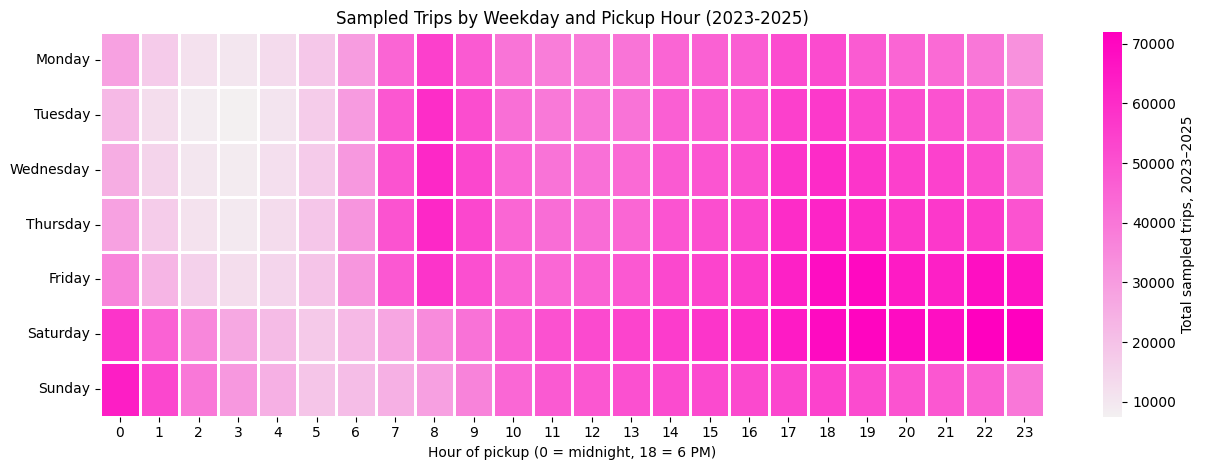

day       hour
Saturday  23      71923
          22      71722
          19      70655
Friday    19      69259
Saturday  18      68742
dtype: int64

In [30]:
grid = visual_trips.groupby(['day', 'hour']).size().unstack(fill_value=0).reindex(index=DAYS, columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.heatmap(grid, cmap=sns.light_palette(PINK, as_cmap=True), linewidths=1, linecolor='white', cbar_kws={'label': 'Total sampled trips, 2023–2025'}, ax=ax)
ax.set_title('Sampled Trips by Weekday and Pickup Hour (2023-2025)')
ax.set_xlabel('Hour of pickup (0 = midnight, 18 = 6 PM)')
ax.set_ylabel('')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

trips_by_hour = visual_trips.groupby(["day", "hour"]).size()
trips_by_hour = trips_by_hour.sort_values(ascending=False)
trips_by_hour.head(5)


**Conclusion:** The results support our hypothesis that Friday and Saturday
evenings have high trip activity. The busiest combination was Saturday
from 11 PM to midnight, with 71,923 sampled trips across 2023–2025,
followed by Saturday from 10 PM to 11 PM with 71,722. Platforms could
prioritize these periods when reviewing driver availability. These counts
are accumulated across the three years, not trips within a single hour.

### Q2. Which pickup zones have the most sampled trips, and how do Uber and Lyft compare?

**Hypothesis:** JFK and LaGuardia are the two busiest pickup zones overall, and Uber has more sampled trips than Lyft in each of the top ten zones.

**Stakeholder relevance:** Help Uber identify locations with concentrated pickup activity and compare its recorded trip volume with Lyft.


Trips included in the zone ranking: 7155191


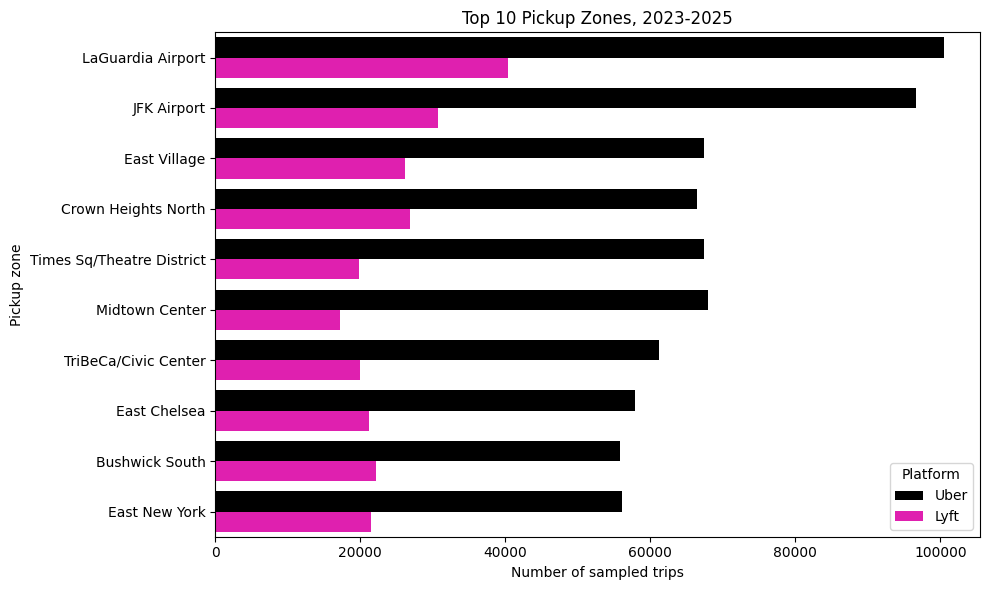

platform,Lyft,Uber,Total
pickup_zone,,,
LaGuardia Airport,40302,100431,140733
JFK Airport,30704,96678,127382
East Village,26095,67457,93552
Crown Heights North,26843,66434,93277
Times Sq/Theatre District,19863,67449,87312
Midtown Center,17263,67902,85165
TriBeCa/Civic Center,20017,61134,81151
East Chelsea,21188,57944,79132
Bushwick South,22106,55837,77943


In [31]:
geographic_trips = visual_trips.loc[visual_trips["platform"].isin(PLATFORMS) & visual_trips["pickup_zone"].notna() & ~visual_trips["pickup_zone"].isin(["Unknown", "N/A", "Outside of NYC"]),["pickup_zone", "platform"]].copy()
print("Trips included in the zone ranking:", len(geographic_trips))

top10 = geographic_trips['pickup_zone'].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(y='pickup_zone', data=geographic_trips.loc[geographic_trips['pickup_zone'].isin(top10)], order=top10, hue='platform', hue_order=PLATFORMS, palette=PLATFORM_COLORS, ax=ax)
ax.set_title('Top 10 Pickup Zones, 2023-2025')
ax.set_xlabel('Number of sampled trips')
ax.set_ylabel('Pickup zone')
ax.legend(title='Platform')
plt.tight_layout()
plt.show()

zone_counts = geographic_trips.groupby(["pickup_zone", "platform"]).size()
zone_counts = zone_counts.unstack(fill_value=0)

zone_counts["Total"] = zone_counts["Uber"] + zone_counts["Lyft"]
zone_counts = zone_counts.sort_values("Total", ascending=False)

zone_counts.head(10)

**Conclusion:** These results support our hypothesis that airport zones have the highest pickup activity. LaGuardia ranked first with 140,733 sampled trips, followed by JFK with 127,382. Uber recorded more trips than Lyft in all ten zones. These results support prioritizing busy pickup locations for planning.

### Q3. How do median passenger waits vary by pickup hour and platform in 2025?

**Hypothesis:** Median waits are higher in the early morning than late morning, and Lyft has longer median waits than Uber in most pickup hours.

**Stakeholder relevance:** Help Uber identify hours with longer passenger waits and compare its service with Lyft.




Trips with valid waits: 2407846
Trips excluded from wait analysis: 28051


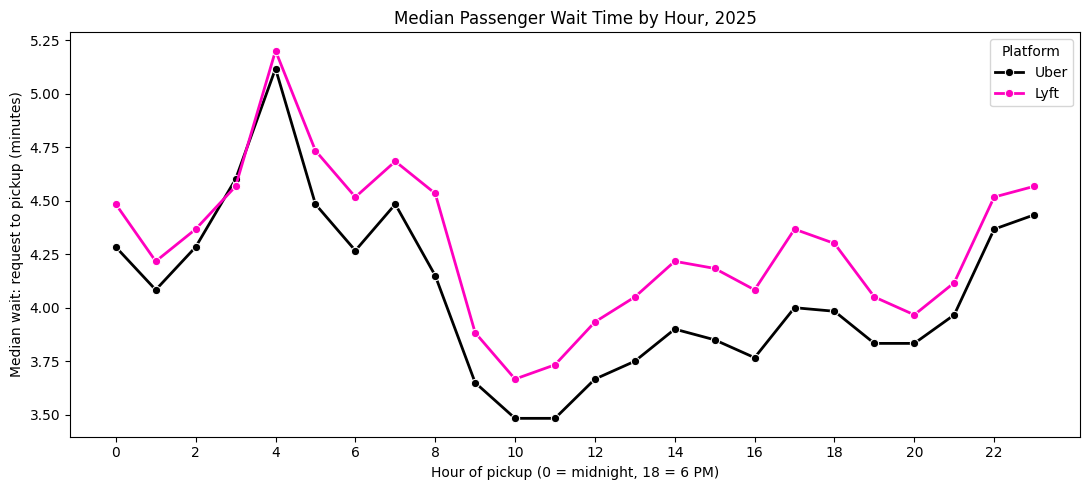

,hour,platform,wait_min
21,10,Uber,3.483333
23,11,Uber,3.483333
19,9,Uber,3.650000
20,10,Lyft,3.666667
25,12,Uber,3.666667


In [32]:
platform_trips = rideshare_clean.loc[(rideshare_clean["year"] == 2025) & rideshare_clean["service_license"].isin(["HV0003", "HV0005"])].copy()
platform_trips["platform"] = platform_trips["service_license"].replace({"HV0003": "Uber", "HV0005": "Lyft"})
platform_trips["hour"] = platform_trips["pickup_hour"]
platform_trips["wait_min"] = platform_trips["wait_time_seconds"] / 60

wait_trips = platform_trips.loc[platform_trips["wait_min"].notna() & (platform_trips["wait_min"] >= 0)]
print("Trips with valid waits:", len(wait_trips))
print("Trips excluded from wait analysis:", len(platform_trips) - len(wait_trips))

wait_by_hour = (wait_trips.groupby(['hour', 'platform'])['wait_min'].median().reset_index())
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(x='hour', y='wait_min', data=wait_by_hour, hue='platform', hue_order=PLATFORMS, palette=PLATFORM_COLORS, linewidth=2, marker='o', markersize=6, ax=ax)
ax.set_title('Median Passenger Wait Time by Hour, 2025')
ax.set_xlabel('Hour of pickup (0 = midnight, 18 = 6 PM)')
ax.set_ylabel('Median wait: request to pickup (minutes)')
ax.set_xticks(range(0, 24, 2))
ax.legend(title='Platform')
plt.tight_layout()
plt.show()

wait_by_hour.sort_values("wait_min", ascending=False).head(5)
wait_by_hour.sort_values("wait_min").head(5)

**Conclusion:** These results support our hypothesis that waits are longer in the early morning and Lyft generally has longer waits than Uber. Both platforms peaked around 4 AM at approximately five minutes. Uber’s lowest median was 3.48 minutes at 10–11 AM, while Lyft’s was 3.67 minutes at 10 AM. Platforms could review early-morning driver availability to identify opportunities to reduce waits.

### Q4. Does seasonal trip activity grow equally across 2023–2025?

**Hypothesis:** Year-over-year growth in average sampled trips per calendar day differs across seasons, with winter increasing in both comparisons.

**Stakeholder relevance:** Help Uber account for differences in seasonal growth when planning driver availability.


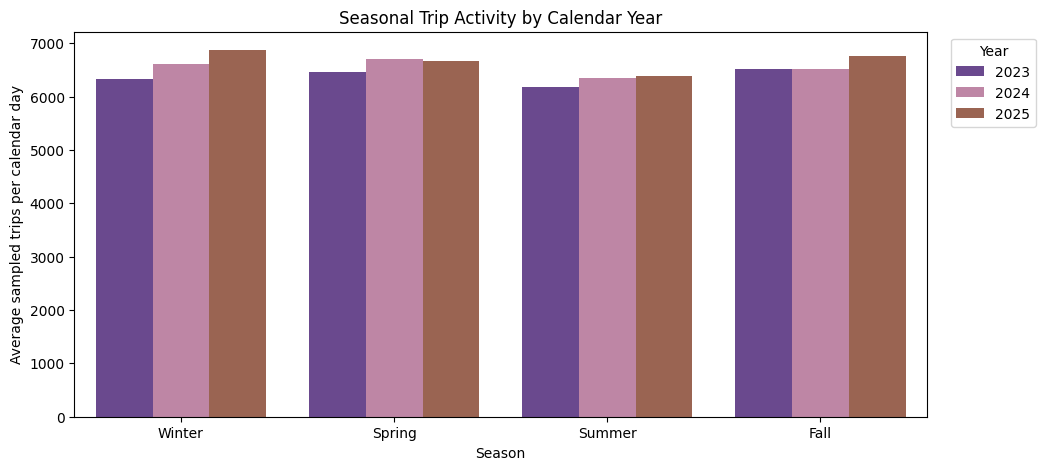

        2024 vs 2023 (%)  2025 vs 2024 (%)
Winter              4.35              4.08
Spring              3.89             -0.54
Summer              2.84              0.61
Fall               -0.14              3.94


In [33]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(data=season_summary, x="season", y="average_daily_trips", hue="year", order=SEASONS, hue_order=YEARS, palette=YEAR_COLORS, ax=ax)

ax.set_title("Seasonal Trip Activity by Calendar Year")
ax.set_xlabel("Season")
ax.set_ylabel("Average sampled trips per calendar day")
ax.legend(title="Year", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=True)

plt.show()

season_by_year = season_summary.pivot(index="season",columns="year",values="average_daily_trips").reindex(SEASONS)

season_growth = pd.DataFrame(index=SEASONS)
season_growth["2024 vs 2023 (%)"] = (season_by_year[2024] / season_by_year[2023] - 1) * 100
season_growth["2025 vs 2024 (%)"] = (season_by_year[2025] / season_by_year[2024] - 1) * 100

print(season_growth.round(2))


**Conclusion:** These results support our hypothesis that growth differs across seasons, with winter increasing in both comparisons. Winter activity grew by 4.35% in 2024 and 4.08% in 2025. In contrast, spring declined by 0.54% in 2025, while fall increased by 3.94%. Platforms should consider each season’s growth pattern when planning driver availability.

### Q5. Do monthly activity patterns repeat across 2023–2025?

**Hypothesis:** Average daily sampled activity is lower in July and August than in the final months of each year.

**Stakeholder relevance:** Help Uber identify recurring quieter and busier months for planning.



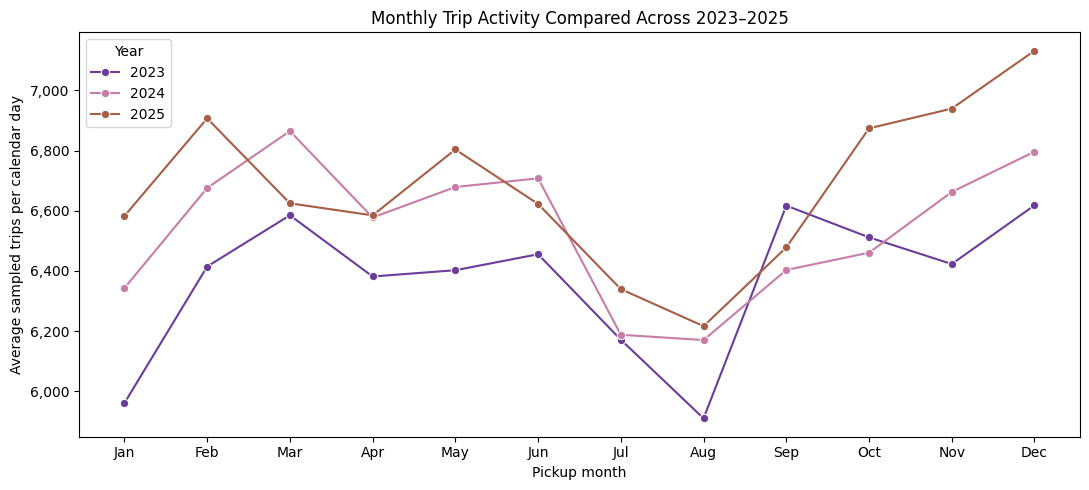

In [34]:
monthly_counts = rideshare_clean.groupby(["year", "month"]).size().reset_index(name="sampled_trips")
monthly_days = calendar_days.groupby(["year", "month"]).size().reset_index(name="calendar_days")
monthly_summary = monthly_days.merge(monthly_counts, on=["year", "month"], how="left", validate="one_to_one")
monthly_summary["average_daily_trips"] = monthly_summary["sampled_trips"] / monthly_summary["calendar_days"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly_summary, x="month", y="average_daily_trips", hue="year", hue_order=YEARS, palette=YEAR_COLORS, marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Monthly Trip Activity Compared Across 2023–2025")
ax.set_xlabel("Pickup month")
ax.set_ylabel("Average sampled trips per calendar day")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Year")
plt.tight_layout()
plt.show()


**Conclusion:** These results support our hypothesis that summer activity is lower than activity toward year-end. August had the lowest average daily sampled trips in all three years, at approximately 5,910 in 2023, 6,170 in 2024, and 6,217 in 2025. December averages were approximately 6,618, 6,796, and 7,132, respectively. Platforms could account for this recurring August dip when planning driver availability.

### Q6: How do passenger wait times vary across seasons and years?

**Hypothesis:** Median passenger wait times are longer in winter than in other seasons, but the difference varies across 2023–2025.
**Stakeholder relevance:** Help Uber assess whether broad seasonal changes in driver availability are supported by passenger wait patterns

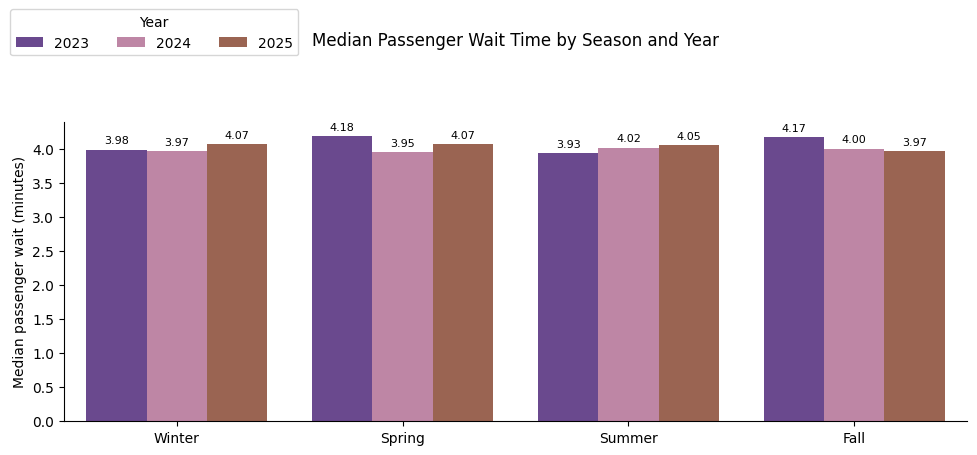

In [35]:
wait_by_season = rideshare_clean.groupby(["season", "year"])['wait_time_seconds'].median().reset_index()
wait_by_season['median_wait'] = wait_by_season['wait_time_seconds']/60
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(data = wait_by_season, x="season", y="median_wait", hue="year", order=SEASONS, hue_order=YEARS, palette=YEAR_COLORS, errorbar=None, ax=ax)
ax.set_title("Wait Times Across Seasons and Years", pad = 12)
ax.set_xlabel("")
ax.set_title("Median Passenger Wait Time by Season and Year", pad=55)
ax.set_ylabel("Median passenger wait (minutes)")
ax.legend(title="Year", loc="upper center", bbox_to_anchor=(0.1, 1.4), ncol=5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding = 3, fontsize = 8)

sns.despine()
plt.tight_layout()
plt.show()

**Conclusion:** These results do not support our hypothesis that winter consistently has longer waits. Seasonal medians ranged from 3.93 to 4.18 minutes, a difference of approximately 15 seconds. Spring had the highest median in 2023, while summer had the highest in 2024. Platforms should examine pickup hours and zones before making broad seasonal changes to driver availability.

### Q7: How do median passenger waits vary across seasons in the ten busiest pickup zones?

**Hypothesis:** Winter median waits are longer than those in other seasons within most of the ten busiest pickup zones.

**Stakeholder relevance:** Help Uber identify busy pickup locations where seasonal waits deserve closer review.



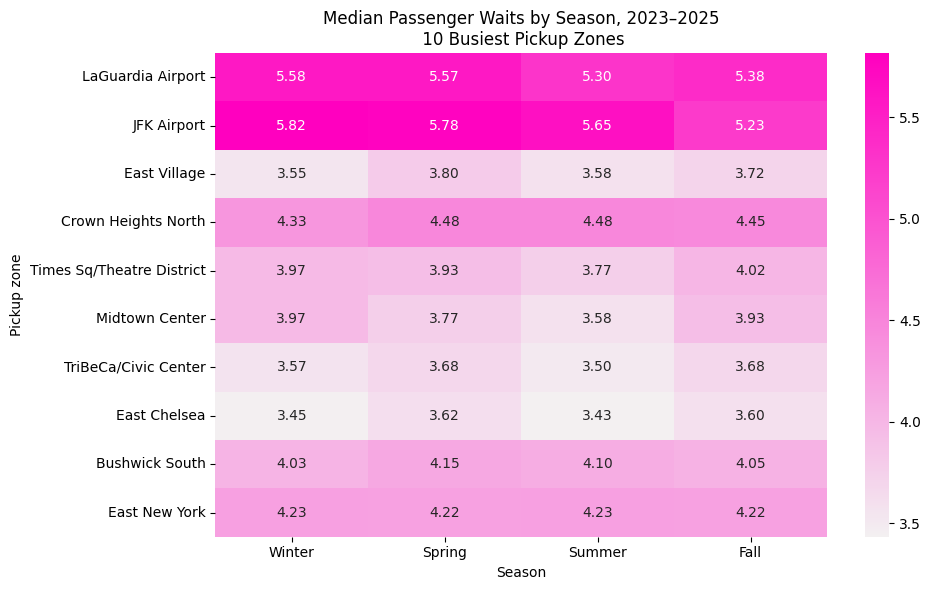

In [36]:
valid_wait = rideshare_clean['wait_time_seconds'].notna() & (rideshare_clean['wait_time_seconds'] >= 0)
df_filtered = rideshare_clean.loc[valid_wait, ['pickup_zone_id', 'season', 'wait_time_seconds']]

pivot_df = df_filtered.pivot_table(index='pickup_zone_id',columns='season',values='wait_time_seconds', aggfunc='median')

pivot_df = pivot_df / 60
pivot_df = pivot_df.reindex(columns=SEASONS)

pivot_df = pivot_df.reset_index()
pivot_df = pivot_df.merge(zones[['pickup_zone_id', 'pickup_zone']], on='pickup_zone_id', how='left')
pivot_df = pivot_df.loc[pivot_df['pickup_zone'].isin(top10)]
pivot_df = pivot_df.set_index('pickup_zone')

top_10_zones = pivot_df[SEASONS].reindex(top10)

plt.figure(figsize=(10, 6))
sns.heatmap(top_10_zones, cmap=sns.light_palette(PINK, as_cmap=True), annot=True, fmt=".2f")

plt.title("Median Passenger Waits by Season, 2023–2025\n 10 Busiest Pickup Zones")
plt.ylabel("Pickup zone")
plt.xlabel("Season")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Conclusion:** These results do not support our hypothesis that winter waits are longest in most busy zones. Winter medians were highest at JFK (5.82 minutes) and LaGuardia (5.58 minutes), but other zones peaked in spring, summer, or fall. JFK’s median fell to 5.23 minutes in fall, while East New York stayed near 4.22–4.23 minutes throughout the year. Platforms should consider each zone’s seasonal pattern when reviewing passenger waits.

### Q8: Do the busiest pickup zones also have the longest passenger waits?

**Hypothesis:** Zones with higher average daily sampled trip activity have longer median passenger waits within the same season.

**Stakeholder relevance:** Help Uber consider pickup activity and passenger waits together when reviewing busy locations.



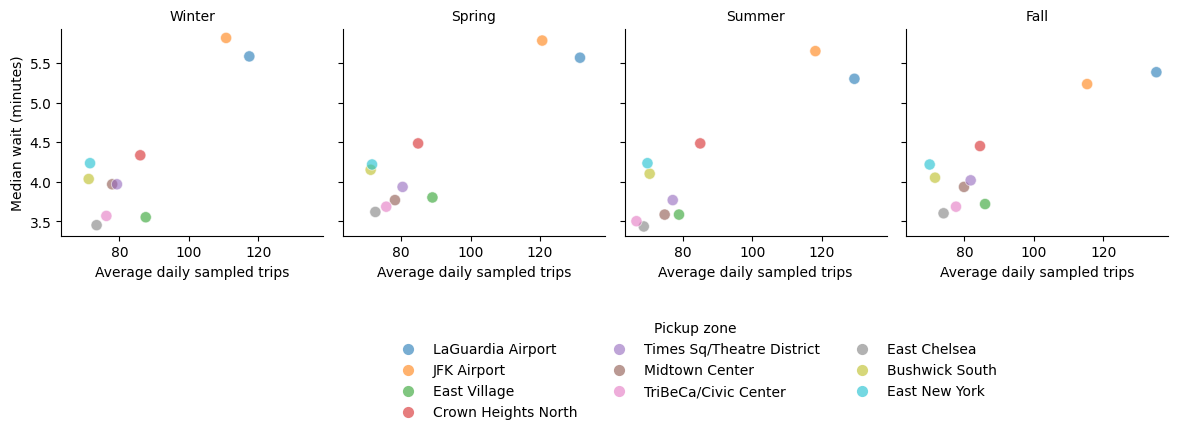

,average_daily_trips,median_wait,valid_waits
count,40.000000,40.000000,40.000000
mean,86.058992,4.235417,23375.375000
std,19.498769,0.724148,5414.143461
min,66.681159,3.433333,18273.000000
25%,72.367754,3.683333,19625.250000
50%,78.585145,4.025000,21214.000000
75%,86.411439,4.458333,23330.000000
max,135.223443,5.816667,36837.000000


In [37]:
zone_season_summary = rideshare_clean.groupby(["pickup_zone_id", "season"]).agg(median_wait=("wait_time_seconds", "median"), sampled_trips=("pickup_zone_id", "size"), valid_waits=("wait_time_seconds", "count")).reset_index()
season_days_all = season_days.groupby("season")["calendar_days"].sum().reset_index()
zone_season_summary = zone_season_summary.merge(season_days_all, on='season', how="left")


zone_season_summary["median_wait"] = zone_season_summary['median_wait'] / 60
zone_season_summary["average_daily_trips"] = zone_season_summary["sampled_trips"] / zone_season_summary["calendar_days"]

zone_season_summary = zone_season_summary.merge(zones[["pickup_zone_id", "pickup_zone"]], on="pickup_zone_id", how="left")
zone_season_summary = zone_season_summary.loc[zone_season_summary["pickup_zone"].isin(top10)]
zone_season_summary = zone_season_summary.loc[zone_season_summary["valid_waits"] >= 30]

g = sns.relplot(data=zone_season_summary, x="average_daily_trips", y="median_wait", col="season", col_order=SEASONS, hue="pickup_zone", hue_order=top10, palette="tab10", kind="scatter", alpha=0.6, s=65, height=3, aspect=1)
g.set_titles("{col_name}")
g.set_axis_labels("Average daily sampled trips", "Median wait (minutes)")
sns.move_legend(g, "upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, title="Pickup zone", frameon=False)
plt.show()

zone_season_summary[["average_daily_trips", "median_wait", "valid_waits"]].describe()


**Conclusion:** These results partly support our hypothesis. Among the ten busiest zones, JFK and LaGuardia combine the highest pickup activity with median waits of approximately 5.2–5.8 minutes across seasons. However, activity and waits do not rise consistently among the other eight zones. Platforms should review airport waits while considering each zone’s activity and wait times together when planning service.

### Q9: How do Uber and Lyft passenger wait times compare after controlling for pickup hour, zone, and trip distance? A comparison at LaGuardia Airport during 7–8 PM in 2025

**Why we selected this controlled setting:** Q2 showed LaGuardia as the busiest pickup zone, while Q1 showed 7 PM among busy evening periods. Our initial 4–5 AM comparison had too few observations, so we selected this busier hour.

**Hypothesis:** Lyft has longer median passenger waits than Uber within the same trip-distance groups at LaGuardia during 7–8 PM.

**Stakeholder relevance:** Help Uber compare passenger waits with Lyft for trips with similar recorded characteristics.






/tmp/ipykernel_69388/434062538.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  airport_waits = airport_trips.groupby(["distance_group", "platform"])["wait_min"].agg(["median", "count"]).reset_index()


  distance_group platform    median  count
0         0–2 mi     Lyft  5.841667      8
1         0–2 mi     Uber  6.233333     31
2         2–5 mi     Lyft  4.725000     56
3         2–5 mi     Uber  5.883333    126
4        5–10 mi     Lyft  4.433333    396
5        5–10 mi     Uber  6.466667   1140
6         10+ mi     Lyft  5.125000    398
7         10+ mi     Uber  6.266667    937


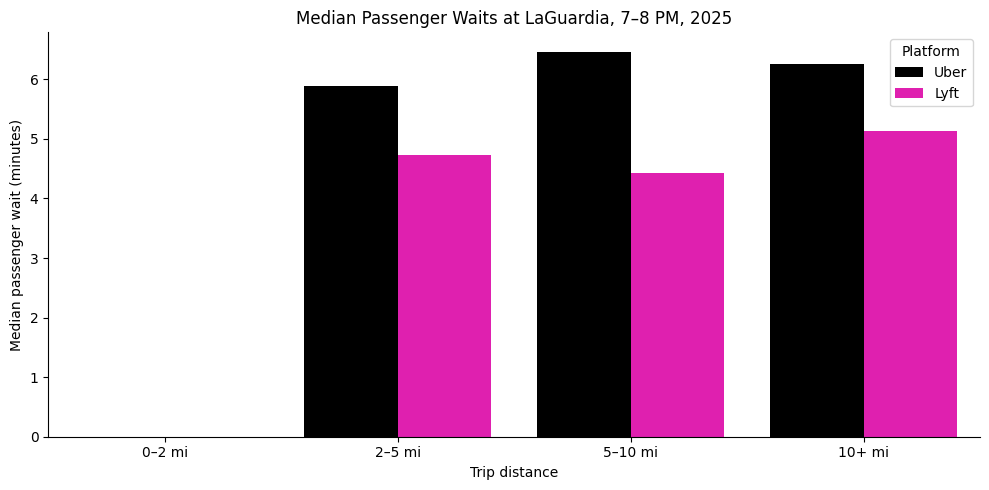

In [38]:
airport_ids = zones.loc[zones["pickup_zone"] == "LaGuardia Airport", "pickup_zone_id"]

airport_trips = rideshare_clean.loc[(rideshare_clean["year"] == 2025) & (rideshare_clean["pickup_hour"] == 19) & rideshare_clean["pickup_zone_id"].isin(airport_ids), ["service_license", "wait_time_seconds", "trip_miles"]].copy()

airport_trips["platform"] = airport_trips["service_license"].replace({"HV0003": "Uber", "HV0005": "Lyft"})
airport_trips = airport_trips.loc[airport_trips["platform"].isin(PLATFORMS)]
airport_trips = airport_trips.loc[airport_trips["wait_time_seconds"] >= 0]
airport_trips = airport_trips.loc[airport_trips["trip_miles"] > 0].copy()

airport_trips["wait_min"] = airport_trips["wait_time_seconds"] / 60
airport_trips["distance_group"] = pd.cut(airport_trips["trip_miles"], bins=[0, 2, 5, 10, float("inf")], labels=["0–2 mi", "2–5 mi", "5–10 mi", "10+ mi"])

airport_waits = airport_trips.groupby(["distance_group", "platform"])["wait_min"].agg(["median", "count"]).reset_index()
print(airport_waits)

wait_counts = airport_waits.pivot(index="distance_group", columns="platform", values="count")
eligible_groups = wait_counts.loc[(wait_counts["Uber"] >= 30) & (wait_counts["Lyft"] >= 30)].index
airport_plot = airport_waits.loc[airport_waits["distance_group"].isin(eligible_groups)]

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=airport_plot, x="distance_group", y="median", hue="platform", hue_order=PLATFORMS, palette=PLATFORM_COLORS, errorbar=None, ax=ax)
ax.set_title("Median Passenger Waits at LaGuardia, 7–8 PM, 2025")
ax.set_xlabel("Trip distance")
ax.set_ylabel("Median passenger wait (minutes)")
ax.legend(title="Platform")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Conclusion:** These results do not support our hypothesis that Lyft has longer waits in this setting. At LaGuardia during 7–8 PM in 2025, Uber had longer median waits in all three eligible distance groups. The largest difference was for 5–10 mile trips: 6.47 minutes for Uber versus 4.43 minutes for Lyft, approximately two minutes. Uber could investigate pickup coordination and driver availability during this period; these findings apply only to the selected location, hour, and year.

### Q10: How does the difference between Uber and Lyft median passenger waits change across seasons in 2023–2025?

**Hypothesis:** The difference between Lyft and Uber median wait times is larger in winter and varies across years.

**Stakeholder relevance:** Help Uber track overall differences in passenger waits across seasons and years.


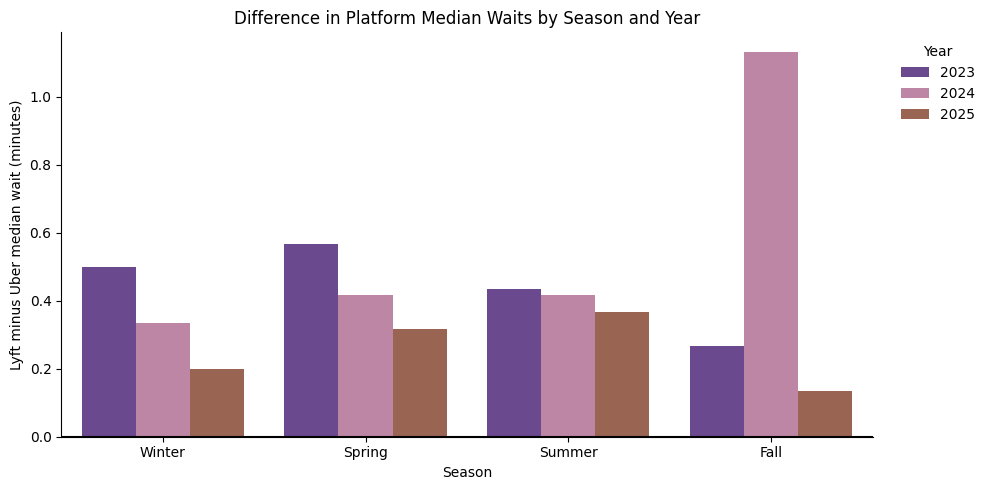

,median,count
platform,,
Lyft,294.0,140805
Uber,226.0,445535


In [39]:
seasonal_waits = rideshare_clean[["year", "season", "service_license", "wait_time_seconds"]].copy()

seasonal_waits["platform"] = seasonal_waits["service_license"].replace({"HV0003": "Uber", "HV0005": "Lyft"})
seasonal_waits = seasonal_waits.loc[seasonal_waits["platform"].isin(PLATFORMS)]
seasonal_waits = seasonal_waits.loc[seasonal_waits["wait_time_seconds"] >= 0]

wait_gap = seasonal_waits.pivot_table(index=["year", "season"], columns="platform", values="wait_time_seconds", aggfunc="median")
wait_gap = wait_gap / 60
wait_gap["lyft_minus_uber"] = wait_gap["Lyft"] - wait_gap["Uber"]
wait_gap = wait_gap.reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=wait_gap, x="season", y="lyft_minus_uber", hue="year", order=SEASONS, hue_order=YEARS, palette=YEAR_COLORS, errorbar=None, ax=ax)
ax.axhline(0, color="black")
ax.set_title("Difference in Platform Median Waits by Season and Year")
ax.set_xlabel("Season")
ax.set_ylabel("Lyft minus Uber median wait (minutes)")
ax.legend(title="Year", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

wait_gap.round(2)

fall_2024 = seasonal_waits.loc[(seasonal_waits["year"] == 2024) & (seasonal_waits["season"] == "Fall")]

fall_2024.groupby("platform")["wait_time_seconds"].agg(["median", "count"])


**Conclusion:** These results do not support our hypothesis that the Uber–Lyft wait-time gap is largest in winter. The largest gap occurred in fall 2024, when Lyft’s median wait was 4.90 minutes compared with Uber’s 3.77 minutes. Uber should examine this gap based on other variables before drawing any conclusions.

### Q11: Are passenger waits longer on days with precipitation?


**Hypothesis:** Median passenger wait time is higher on days with precipitation than on dry days.

**Stakeholder relevance:** Help Uber assess whether daily precipitation is associated with a substantial overall difference in passenger waits.

  weather_condition    median    count
0               Dry  4.000000  3760128
1     Precipitation  4.066667  3321042


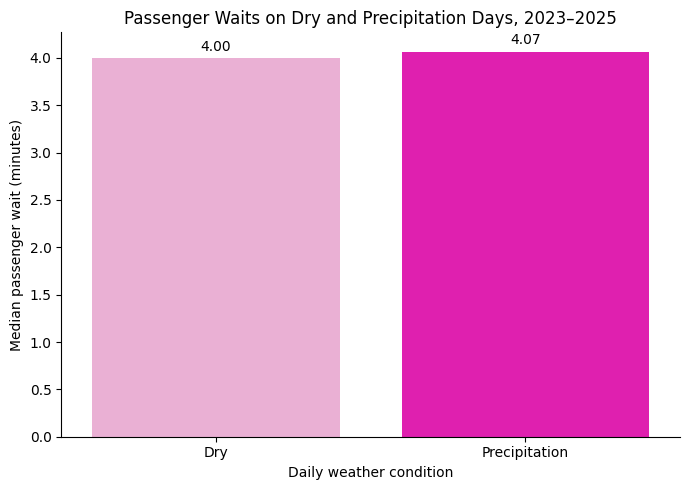

In [40]:
weather_trips = visual_trips.loc[(visual_trips["wait_min"] >= 0) & visual_trips["platform"].isin(PLATFORMS), ["pickup_datetime", "wait_min"]].copy()

weather_trips["trip_date"] = weather_trips["pickup_datetime"].dt.normalize()

weather_trips = weather_trips.merge(weather_daily[["DATE", "weather_condition"]], left_on="trip_date", right_on="DATE", how="left", validate="many_to_one")
weather_waits = weather_trips.groupby("weather_condition")["wait_min"].agg(["median", "count"]).reset_index()
print(weather_waits)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=weather_waits, x="weather_condition", y="median", order=["Dry", "Precipitation"], hue="weather_condition", palette={"Dry": "#F4A6D7", "Precipitation": PINK}, legend=False, errorbar=None, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title("Passenger Waits on Dry and Precipitation Days, 2023–2025")
ax.set_xlabel("Daily weather condition")
ax.set_ylabel("Median passenger wait (minutes)")
ax.set_ylim(bottom=0)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Conclusion:** These results support our hypothesis that passenger waits are longer on days with precipitation, but the difference is small. Median waits were 4.07 minutes on precipitation days compared with 4.00 minutes on dry days, a difference of approximately four seconds. This overall comparison provides limited support for changing driver availability based on precipitation alone. Further comparisons by season and pickup zone may reveal differences hidden in the combined results.

### Q12: Does winter trip activity increase across years on both dry days and days with precipitation?

**Hypothesis:** Average daily sampled winter trips increase from 2023 to 2025 on both dry days and days with precipitation, consistent with Q4’s winter growth finding.

**Stakeholder relevance:** Help Uber assess whether Q4’s winter growth pattern appears under both weather conditions.


   year weather_condition  sampled_trips  days  average_daily_trips
0  2023               Dry         271553    42          6465.547619
1  2023     Precipitation         298010    48          6208.541667
2  2024               Dry         292537    44          6648.568182
3  2024     Precipitation         308382    47          6561.319149
4  2025               Dry         360545    53          6802.735849
5  2025     Precipitation         257991    37          6972.729730


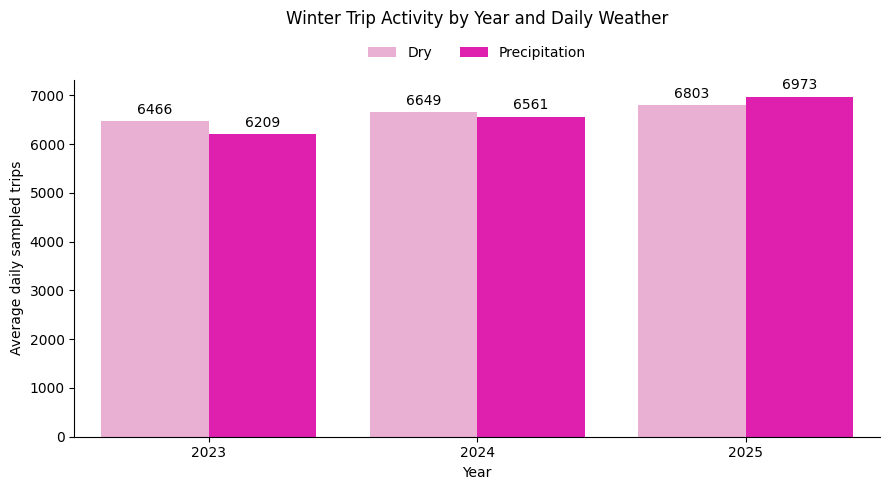

In [41]:
daily_weather_activity["year"] = daily_weather_activity["trip_date"].dt.year

winter_activity = daily_weather_activity.loc[daily_weather_activity["trip_date"].dt.month.isin([1, 2, 12]) & daily_weather_activity["weather_condition"].isin(["Dry", "Precipitation"])].copy()

winter_weather_summary = winter_activity.groupby(["year", "weather_condition"]).agg(sampled_trips=("sampled_trips", "sum"), days=("trip_date", "nunique")).reset_index()
winter_weather_summary["average_daily_trips"] = winter_weather_summary["sampled_trips"] / winter_weather_summary["days"]
print(winter_weather_summary)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=winter_weather_summary, x="year", y="average_daily_trips", hue="weather_condition", order=YEARS, hue_order=["Dry", "Precipitation"], palette={"Dry": "#F4A6D7", "Precipitation": PINK}, errorbar=None, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.set_title("Winter Trip Activity by Year and Daily Weather")
ax.set_xlabel("Year")
ax.set_ylabel("Average daily sampled trips")
ax.set_ylim(bottom=0)
ax.margins(y=0.15)
ax.legend(title=None, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
ax.set_title("Winter Trip Activity by Year and Daily Weather", pad=40)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Conclusion:** These results support our hypothesis that average daily sampled winter trips increased across 2023–2025 under both weather conditions. Dry day activity rose from 6,466 to 6,803 trips per day, while precipitation day activity rose from 6,209 to 6,973. This also extends Q4’s finding by showing growth in both categories. Platforms should consider this broader growth when planning winter driver availability, although the comparison does not establish what caused it.

### Q13: How does average daily pickup activity differ between dry days and precipitation days across the ten busiest zones?

**Hypothesis:** Average daily sampled pickup activity is higher on precipitation days in most of the ten busiest zones.

**Stakeholder relevance:** Help Uber assess whether weather-related activity patterns differ across busy pickup locations.


                  pickup_zone weather_condition  average_daily_trips
0              Bushwick South               Dry            69.563667
1              Bushwick South     Precipitation            72.919132
2         Crown Heights North               Dry            84.202037
3         Crown Heights North     Precipitation            86.157791
4                East Chelsea               Dry            70.848896
5                East Chelsea     Precipitation            73.771203
6               East New York               Dry            70.288625
7               East New York     Precipitation            71.321499
8                East Village               Dry            82.831919
9                East Village     Precipitation            88.291913
10                JFK Airport               Dry           116.071307
11                JFK Airport     Precipitation           116.402367
12          LaGuardia Airport               Dry           129.994907
13          LaGuardia Airport     

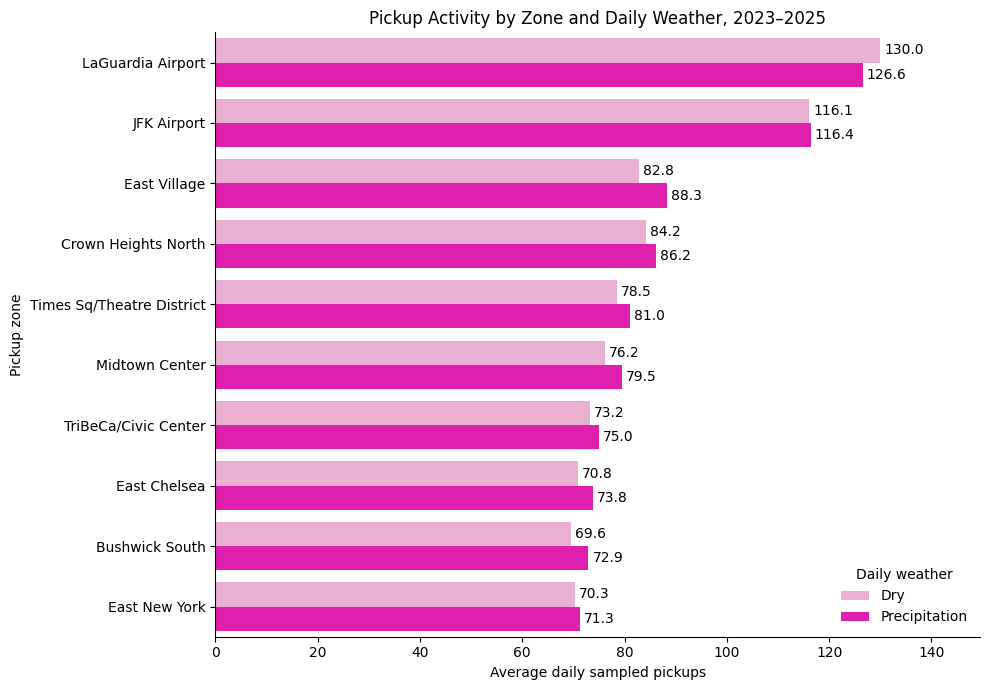

In [42]:
busy_zone_ids = zones.loc[zones["pickup_zone"].isin(top10), "pickup_zone_id"]

zone_daily_activity = rideshare_clean.loc[rideshare_clean["pickup_zone_id"].isin(busy_zone_ids) & rideshare_clean["service_license"].isin(["HV0003", "HV0005"])].groupby(["trip_date", "pickup_zone_id"]).size().reset_index(name="sampled_trips")

zone_daily_activity["trip_date"] = pd.to_datetime(zone_daily_activity["trip_date"])
zone_daily_activity = zone_daily_activity.merge(weather_daily[["DATE", "weather_condition"]], left_on="trip_date", right_on="DATE", how="left")

weather_days = weather_daily.groupby("weather_condition")["DATE"].nunique().reset_index(name="days")

zone_weather_activity = zone_daily_activity.groupby(["pickup_zone_id", "weather_condition"])["sampled_trips"].sum().reset_index()
zone_weather_activity = zone_weather_activity.merge(weather_days, on="weather_condition", how="left")
zone_weather_activity = zone_weather_activity.merge(zones[["pickup_zone_id", "pickup_zone"]], on="pickup_zone_id", how="left")
zone_weather_activity["average_daily_trips"] = zone_weather_activity["sampled_trips"] / zone_weather_activity["days"]

print(zone_weather_activity[["pickup_zone", "weather_condition", "average_daily_trips"]])

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=zone_weather_activity, x="average_daily_trips", y="pickup_zone", order=top10, hue="weather_condition", hue_order=["Dry", "Precipitation"], palette={"Dry": "#F4A6D7", "Precipitation": PINK}, errorbar=None, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.set_title("Pickup Activity by Zone and Daily Weather, 2023–2025")
ax.set_xlabel("Average daily sampled pickups")
ax.set_ylabel("Pickup zone")
ax.margins(x=0.15)
ax.legend(title="Daily weather", frameon=False)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Conclusion:** These results support our hypothesis that pickup activity is higher on precipitation days in most of the ten busiest zones. East Village averaged approximately 88 sampled pickups per precipitation day compared with 83 per dry day. However, LaGuardia recorded fewer pickups on precipitation days, and JFK showed little difference. These patterns suggest that weather related activity comparisons should consider individual pickup locations. They do not establish that precipitation caused the differences.

### Q14: How does median passenger base fare per mile differ between dry days and precipitation days for Uber and Lyft?

**Hypothesis:** Median passenger base fare per mile is higher on precipitation days for both platforms.

**Stakeholder relevance:** Help Uber compare passenger pricing across daily weather conditions alongside the activity and wait patterns examined earlier.

Trips without weather conditions: 0
  weather_condition platform    median    count
0               Dry     Lyft  6.101502  1022533
1               Dry     Uber  6.218463  2776547
2     Precipitation     Lyft  6.127855   908935
3     Precipitation     Uber  6.264407  2445457


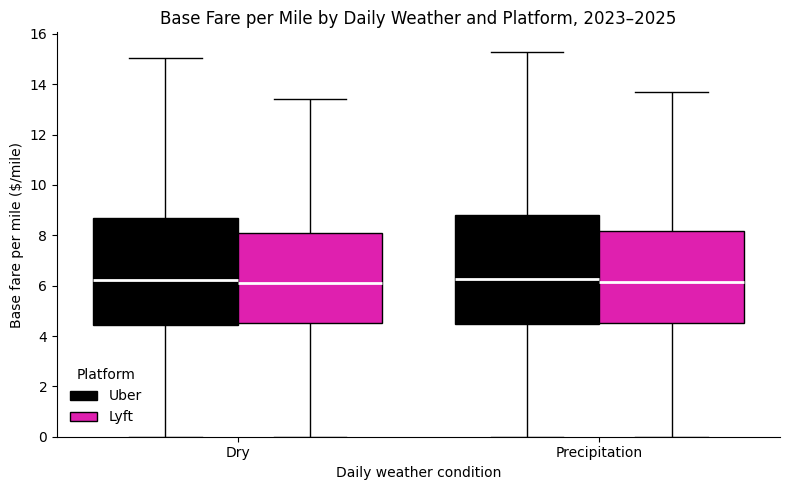

In [43]:
fare_trips = rideshare_clean.loc[(rideshare_clean["trip_miles"] > 0) & (rideshare_clean["base_passenger_fare"] >= 0) & rideshare_clean["service_license"].isin(["HV0003", "HV0005"]), ["trip_date", "service_license", "base_passenger_fare", "trip_miles"]].copy()

fare_trips["platform"] = fare_trips["service_license"].replace({"HV0003": "Uber", "HV0005": "Lyft"})
fare_trips["fare_per_mile"] = fare_trips["base_passenger_fare"] / fare_trips["trip_miles"]
fare_trips["trip_date"] = pd.to_datetime(fare_trips["trip_date"])

fare_trips = fare_trips.merge(weather_daily[["DATE", "weather_condition"]], left_on="trip_date", right_on="DATE", how="left", validate="many_to_one")
print("Trips without weather conditions:", fare_trips["weather_condition"].isna().sum())

weather_fares = fare_trips.groupby(["weather_condition", "platform"])["fare_per_mile"].agg(["median", "count"]).reset_index()
print(weather_fares)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=fare_trips, x="weather_condition", y="fare_per_mile", hue="platform", order=["Dry", "Precipitation"], hue_order=PLATFORMS, palette=PLATFORM_COLORS, showfliers=False, medianprops={"color": "white", "linewidth": 2}, ax=ax)

ax.set_title("Base Fare per Mile by Daily Weather and Platform, 2023–2025")
ax.set_xlabel("Daily weather condition")
ax.set_ylabel("Base fare per mile ($/mile)")
ax.set_ylim(bottom=0)
ax.legend(title="Platform", frameon=False)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Q15: How does median driver pay per recorded trip hour vary by pickup hour and platform?

**Hypothesis:** Median driver pay per recorded trip hour is higher during the busy evening pickup hours identified in Q1 than during midday hours.

**Stakeholder relevance:** Help Uber review recorded driver compensation alongside trip activity and passenger waits when considering incentive pay.


Trips excluded from pay analysis: 760


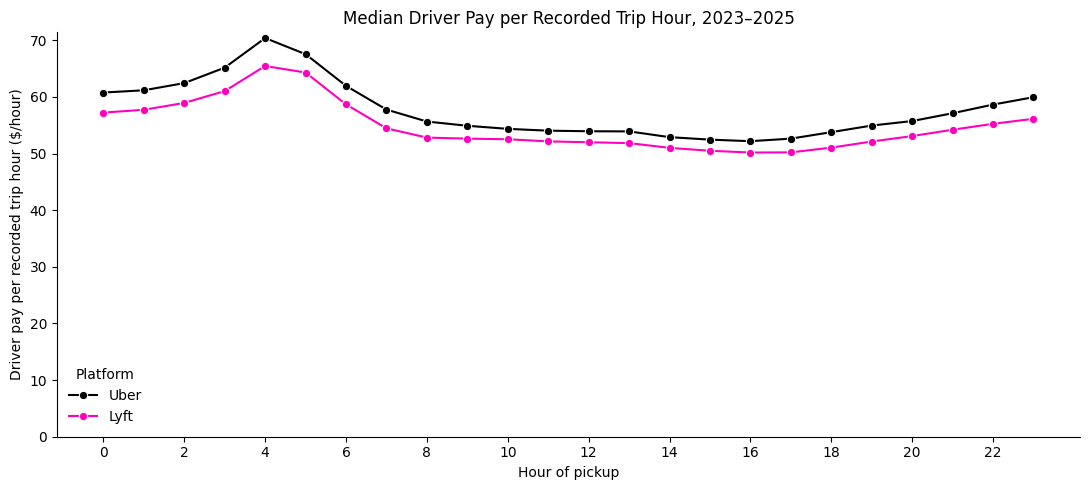

In [44]:
pay_trips = rideshare_clean.loc[rideshare_clean["service_license"].isin(["HV0003", "HV0005"]), ["pickup_hour", "service_license", "driver_pay", "trip_duration_seconds", "pickup_datetime", "dropoff_datetime"]].copy()

pay_trips["calculated_duration"] = (pay_trips["dropoff_datetime"] - pay_trips["pickup_datetime"]).dt.total_seconds()
pay_trips["duration_difference"] = (pay_trips["calculated_duration"] - pay_trips["trip_duration_seconds"]).abs()

trips_before = len(pay_trips)
pay_trips = pay_trips.loc[(pay_trips["driver_pay"] >= 0) & (pay_trips["trip_duration_seconds"] > 0) & (pay_trips["calculated_duration"] > 0) & (pay_trips["duration_difference"] <= 60)].copy()
print("Trips excluded from pay analysis:", trips_before - len(pay_trips))

pay_trips["platform"] = pay_trips["service_license"].replace({"HV0003": "Uber", "HV0005": "Lyft"})
pay_trips["pay_per_trip_hour"] = pay_trips["driver_pay"] / (pay_trips["trip_duration_seconds"] / 3600)

hourly_pay = pay_trips.groupby(["pickup_hour", "platform"])["pay_per_trip_hour"].agg(["median", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=hourly_pay, x="pickup_hour", y="median", hue="platform", hue_order=PLATFORMS, palette=PLATFORM_COLORS, marker="o", ax=ax)

ax.set_title("Median Driver Pay per Recorded Trip Hour, 2023–2025")
ax.set_xlabel("Hour of pickup")
ax.set_ylabel("Driver pay per recorded trip hour ($/hour)")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.legend(title="Platform", frameon=False)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

##4. After Exploratory Questions:
- How could hourly ether data provide additional insights into rideshare demand and passenger waiting time?

Our analysis used daily weather summaries, including precipitation and average temperature. Future research could incorporate hourly weather observations to investigate how short-term changes in weather relate to rideshare activity and passenger waiting times throughout the day. This would provide a more detailed understanding of weather-related demand patterns that daily averages may not capture.



- How could including more competitors provide a better understanding of NYC’s rideshare market?

Our analysis focused on Uber and Lyft, limiting our comparison to two major rideshare platforms. Future research could include additional competitors, such as Pricedive and other for-hire vehicle services, where data is available.  Expanding the analysis would provide a broader perspective on market competition, help identify differences in pricing, demand, and passenger waiting times, and offer a more comprehensive understanding of NYC’s rideshare industry.  

- How does Uber’s commission vary across seasons and weather conditions?

Our analysis focused on driver earnings but did not examine the relationship between customer fares and the amount retained by Uber.  Future research could compare passenger payments with driver compensation to estimate Uber’s commission or platform take rate. Analyzing these differences across seasons and weather conditions, particularly during winter and rainy days, could reveal whether Uber retains a higher proportion of customer payments during periods of potentially increased demand.

## 5. Conclusions:
After we analyzed our data we can see that it suggests Uber should consider pickup timing, location, and seasonal growth together when assessing driver availability. Friday and Saturday evenings had high trip activity, and we saw that the longest hourly median waits occurred around 4 AM in 2025, suggesting these times need more attention. The data shows that average daily sampled winter trips increased by 4.35% in 2024 and 4.08% in 2025, while August consistently had the lowest activity. Airports also need attention as LaGuardia and JFK were the busiest pickup zones, and Uber’s median wait for 5–10 mile trips at LaGuardia during 7–8 PM in 2025 was 6.47 minutes compared with Lyft’s 4.43 minutes. Weather comparisons showed only small overall differences in waits and base fares, with pickup activity varying by zone. Driver pay per recorded trip hour provides another variable to review alongside activity and waits, although it excludes time between trips and expenses. These findings provide starting points for Uber to investigate and test, rather than proof of driver shortages or evidence that higher pay would increase availability.

## 6. Limitations

- Temporal Granularity of Weather Data: Our analysis relies on daily weather summaries rather than hourly data, which averages out brief events, such as a sudden 30 minute downpour during rush hour. Because this hides the immediate impacts on trip volumes and wait times, operations and dispatch teams would not be able to use these daily models to design real time dynamic pricing algorithms or deploy localized driver incentives during sudden weather shifts.
- Binary Classification of Weather: By grouping weather into simple wet or dry days, this analysis treats light rain the same as severe storms or heavy snow. This approach misses how bad the weather actually is, which hides changes in rider demand and driver supply during extreme weather. As a result, planners and business analysts cannot figure out the exact point when service quality drops or when safety measures should be put in place.
- Spatial Granularity of Weather Data: Using just one weather station at LaGuardia Airport to cover all pickup areas misses small weather differences and local rain across different boroughs. This citywide view leaves out specific weather changes in each neighborhood. As a result, local managers cannot clearly see how each area is doing or move drivers to where they are needed during local weather events.
- Exclusion of Unmet Demand: This dataset only records completed trips and wait times, leaving out canceled rides, unfulfilled requests, and closed app sessions. While the results clearly show overall trip patterns, they cannot measure real rider demand or driver shortages during bad weather. As a result, company leaders and planners risk missing how much money was lost and how unhappy customers became when weather disrupted service.

## 7. Recommendations
- Uber Operations: Focus driver supply during peak demand hours, particularly Friday and Saturday evenings, with specific attention on Saturday from 10 PM to midnight. Implement Uber driver promotions or targeted Quest bonuses only in zones where trip demand aligns with extended wait times.\
- Uber Driver Supply and Workforce Planning: Develop distinct driver supply strategies for August and December. Because August consistently records the lowest daily trip volume, Uber should adjust driver onboarding schedules and incentive spending before each seasonal shift.
- Uber Dynamic Pricing Strategy: Analyze hourly rain data within specific pickup zones and trip distance tiers before adjusting Uber surge multipliers during weather events. Daily aggregate data shows that median base fares per mile stay steady across wet and dry conditions, so surge pricing should respond to zone level demand spikes rather than broad weather tags.




##8. Works Cited

- National Centers for Environmental Information. “Local Climatological Data (LCD).” *National Oceanic and Atmospheric Administration*, https://www.ncei.noaa.gov/products/land-based-station/local-climatological-data. Accessed 19 Oct. 2026.

- Weather files used: LaGuardia Airport station USW00014732, daily summaries for 2023, 2024, and 2025.

- New York City Taxi and Limousine Commission. “Taxi Zone Lookup Table.” *NYC.gov*, https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv. CSV file. Accessed 19 Oct. 2026.

- New York City Taxi and Limousine Commission. “TLC Trip Record Data.” *NYC.gov*, https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page. Accessed 19 Oct. 2026.

- Trip files used: High Volume For-Hire Vehicle (HVFHV) monthly Parquet files, January 2023 through December 2025.

##9. Generative AI disclosure

## Random Sampling:

Melis: I used ChatGPT to help us write a for loop for random sampling all months between 2023 to 2025.

## Data Cleaning:
Elizabeth:
- ChatGPT was also  used during the data-cleaning process to help troubleshoot potential errors in planned Python code and provide reminders about specific pandas commands and syntax.
- It was also used to clarify unexpected outputs and suggest ways to check for issues such as duplicates, missing values, incorrect data types, and inconsistencies between pickup and drop-off times.
- These suggestions were used as guidance while cleaning the dataset. Final cleaning decisions and interpretation of the results completed independently.
- ChatGPT was used to refine the language, grammar, and structure of the final presentation. This included improving the wording of exploratory questions, making explanations of analytical findings clearer and more concise, and polishing the descriptions of future research opportunities. All research questions, analytical insights, and future research ideas were originally developed by the team.

## Visuals:
From team assignment 1:
Q5: We used Claude to format and added this line:
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

Teddy:
- Used Prof AI to help fix an error (parenthesis error and merge error) and saw I was trying to merge a non existent column and then proceeded to make sure I was merging accurately after that error.
- Used Prof AI to identify the correct column and understand how to group passenger wait times by both season and year (Q6)
- Used Prof AI to help with calculating median wait time, sampled trip counts, and valid wait time observations using an .agg() example from a previous problem to better understand what I was grouping and using size vs count
- Used Prof AI to understand why I needed to divide sampled trips by calendar days to calculate average daily sampled trips(Q8) to assist with what information I needed to answer the posed question
- Used Prof AI to ask all the inputs for relplot and used the basic format to then put in the information I needed and asked how to label axis from there
- Used Prof AI to help enhance charts for Q6 and Q8 and used adding space between charts and titles, adding values above charts, grid lines, legend, and despine in the final code to help make the chart more visually appealing
- Used Chat to ask when it is easier to use .agg() versus writing multiple lines of code as I was previously trying to do and then submitted put my own code as an example to check accuracy

Taaseen:
- I used Claude to fix the formatting of the visuals, such as setting hue, tight_layout, bar_label, set_xticks, y_ticks, frameon etc.
- I used Claude to troubleshoot and debugg the code for the visuals.  

Sally:
- I used Prof AI to troubleshoot and resolve Python code errors and make sure the formatting for the visuals are correct
- I used Gemini to consulted for customized graph color maps (cmap) and styling options for data visualizations.
- I ised to assist with code syntax in Question 7, specifically for reindexing seasonal column order and formatting heatmap annotations (pivot_df.reindex(columns=SEASONS), annot=True, fmt=".2f").

Melis:
- Moved the hue's that were not readable and covering the graph with ChatGPT. It introduced this line: "sns.move_legend(g, "upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, title="Pickup zone", frameon=False)"
- I asked ChatGPT how to put the number labels to the columns for Q13 and it added this code:
"for container in ax.containers: ax.bar_label(container, fmt="%.1f", padding=3)"
- For Q14 ChatGPT helped me to add the median line to the boxplot.

## Formatting:

Melis:
- I got help from ChatGPT to organize and document 2.2 Data Dictionary, then checked the descriptions against our dataset columns and source documentation.

- I used ChatGPT to help us when the session crashed because of RAM limit, it helped us write code to use our RAM effectively. For example: del rideshare
gc.collect()


